# Brush GPT: Painting Cat Faces Stroke by Stroke with an Autoregressive Transformer

## Abstract

I study an unconditional generation problem: starting from a blank canvas, with no photograph, text or class label
as input, a model paints a cat that does not exist, **one brush stroke at a time**. Its output is not a grid of pixels
but a sequence of interpretable oil-paint strokes, each with an explicit position, orientation, size, colour and
opacity.

To obtain training data, I convert real cat-face photographs into stroke sequences with a differentiable renderer:
every painting consists of exactly 608 strokes laid down in four coarse-to-fine stages. Each stroke is discretised
into five tokens, and a decoder-only Transformer with 27.9 million parameters is trained to predict the next token.
The training set contains 3,413 cats from AFHQ; an experiment in progress adds 6,327 cats from the CAT dataset.

To measure whether the generated faces are structurally correct, I use a cat-face landmark model trained only on
photographs as an **independent judge** of how recognisable the eyes are. Three design choices raise the eye score of
generated paintings from 0.84 to 0.91 of that of real paintings: writing nine facial keypoints first as a
compositional plan, up-weighting the loss on strokes around the eyes, and aligning every face to a canonical
position. Along the same progression, the FID against the training paintings falls from 209 to 182, and no
generated painting is closer to the training set than an unseen real painting is. Against held-out test paintings,
however, the full model reaches an FID of 196, compared with 49 for real paintings: the generated distribution
remains far from the real one.

To locate where the errors arise, I give the model the first *k* stages of a real painting, let it complete the
rest, and compare the result with the same cat's full painting. The eyes are lost mainly in the **two finest stages**,
which are also the stages with the lowest per-token loss. Per-token loss therefore cannot tell where the visible
errors occur; they have to be measured on the rendered painting with a structural judge.

Finally, I am extending the fact that the output is a sequence of strokes to **attribute-controlled painting with
local editing** (work in progress, not yet complete). A user specifies the cat's appearance, for example turning a
black cat into a white cat with heart-shaped patches on its crown, a blue left eye and a green right eye, and the
model paints under that condition. Because the painting process can be watched and every stroke can be edited or
removed on its own, each later change should require repainting only the strokes in the affected region rather
than the whole picture. The attribute definition, the measurement of attributes on photographs, and a reader that
extracts them from coloured doodles are complete; the attribute-conditioned Brush GPT and local repainting have not
yet been implemented.

**Keywords:** stroke-based rendering, autoregressive generation, discrete tokens, Transformer, generative model
evaluation, conditional generation, local editing

**Evidence rule.** Every number in this notebook comes from one of three sources, all listed in Appendix E:
*computed here* (by the code below, from files the experiments saved), *quoted* (copied from a project document
because the raw output was not kept as a file), or *not measured*. The notebook neither trains nor samples any
model; it only reads saved logs and metrics, and decodes and renders saved tokens on the CPU.

In [1]:
import json
import os
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

os.environ["BRUSHGPT_DEVICE"] = "cpu"             # this notebook uses the CPU only
ML = Path.cwd().parent                            # the notebook lives in ml/notebooks
sys.path.insert(0, str(ML))
LAND = Path.home() / "Digipen fall 2026" / "cat-face-landmarks"
RUNS, TOK = ML / "runs/brushgpt", ML / "data/processed/brushgpt"
NAMES = ["C_overlap_heads", "D_all_cats", "E_points", "F_eye_weight", "G_points_eyes", "H_aligned",
         "I_aligned_points_eyes"]
# descriptive names of the runs (Appendix D maps them to run codes)
LABEL = {"C_overlap_heads": "Small data", "D_all_cats": "Baseline", "E_points": "+Points", "F_eye_weight": "+Eye weight",
         "G_points_eyes": "+Points +eye weight", "H_aligned": "+Aligned", "I_aligned_points_eyes": "Full model"}
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

USED, VERIFY = [], []                             # every file read; every number with its source (Appendix E)


def need(path):
    path = Path(path)
    USED.append(path)
    return path


def jl(path):
    return [json.loads(line) for line in open(need(path))]


def show(path, box=None, figsize=(11, 4)):
    im = Image.open(need(path)).convert("RGB")
    if box:
        im = im.crop(box)
    plt.figure(figsize=figsize)
    plt.imshow(im)
    plt.axis("off")
    plt.show()


def ver(claim, value, source, kind):
    '''Register a number for Appendix E. kind: computed here / quoted / not measured.'''
    VERIFY.append((claim, value, source, kind))
    return value


from sellanything_ml.sketch import brushgpt as G       # decoding and rendering only; no model is built
from sellanything_ml.sketch import brushtokens as T
from sellanything_ml.sketch import catbrush as B

print("loaded; device:", os.environ["BRUSHGPT_DEVICE"])

loaded; device: cpu


## 1. Introduction

### 1.1 Problem

Recent image generators, such as diffusion models and autoregressive pixel models, output a finished raster image.
Human painters do not work this way. An oil painting is built up one stroke at a time: broad strokes lay in blocks of
colour first, and progressively smaller brushes add structure and detail, each stroke with a definite position,
direction, size and colour. If a model's output is itself a sequence of strokes, then (1) the generation *process*
can be watched, (2) every stroke can be edited or removed on its own, and (3) one can ask directly at which stroke,
and in which stage, the model goes wrong.

I study the hardest version of this problem: **unconditional generation**. The model sees no photograph, text or
class label; it starts from a blank canvas, decides every stroke itself, and paints a cat that is not in the training
data. I chose cat faces because they have a clear structure that can be checked objectively (two eyes, a nose, a
mouth and two ears), and because the eyes are both the part most likely to fail and the failure a viewer notices
first.

**Extension: specified appearance and local editing (in progress, not yet complete).** Properties (1) and (2) also
enable a different use. A user can specify the cat's appearance, for example turning a black cat into a white cat
with heart-shaped patches on its crown, a blue left eye and a green right eye, and the model paints it stroke by
stroke under that condition. When the user then changes a single detail, say the right eye from green to blue, only
the strokes in the small region tied to that detail (around the right eye) should need to be regenerated, because
the painting is a sequence of strokes that can each be edited or removed. All other strokes stay as they are, and the
user can watch that small region being repainted. A pixel-based generator would have to regenerate the whole image
for the same change, or rely on a separately trained inpainting mechanism; a stroke sequence naturally decomposes the
picture into units that can be located and replaced. The core of this paper (Sections 3–11) remains unconditional
generation. The definition of appearance attributes and the methods for reading them from photographs and doodles are
complete and reported in Section 13; the attribute-conditioned model and local repainting are not yet implemented,
and Section 13.9 describes the planned approach and how it will be evaluated.

### 1.2 Why it is hard

* **Long sequences.** Every cat is exactly 608 strokes of five tokens each. With the structural markers and face
  points, a painting is 3,064 tokens, so the model makes 3,063 successive predictions, and later strokes inherit
  earlier mistakes.
* **Five heterogeneous fields per stroke.** Position is a geometric quantity, whereas colour is a discrete value among
  6,912 classes; the two differ completely in difficulty and distribution.
* **Ambiguous stroke order.** All strokes within a stage are optimised jointly, so their order in the list carries no
  meaning; yet where two strokes overlap, their order determines the picture.
* **Little data.** Only a few thousand to ten thousand cat faces can be converted into strokes by the same painter,
  far below the scale common in image generation.
* **Structurally correct is not the same as close in pixels.** A painting can have the right overall colours and
  outline while its eyes are a blur; neither the FID nor the loss reveals this.

### 1.3 Research questions and contributions

The paper is organised around five research questions. Each is followed by my answer or contribution and the
sections where it appears.

**RQ1:** If oil-paint strokes are discretised into tokens and a standard decoder-only Transformer predicts them one
token at a time, can it learn to generate paintings that are decodable, look like cats, and do not copy the training
data?
→ I build a complete pipeline from photographs to learnable stroke sequences: landmark labelling, data filtering, a
painter based on differentiable rendering, tokenisation with a fixed layout, and a reordering of strokes that leaves
the picture unchanged (Sections 3 and 4). A model trained on this data generates decodable, cat-like paintings that
do not copy the training data (Sections 8.1 and 8.3).

**RQ2:** Which design choices improve *structure*, with the eyes as its representative?
→ I propose a **structural evaluation** that uses an independent landmark model as the judge and compares data
versions fairly through the ratio of generated to real scores (Section 7.2). I compare a compositional plan (writing
the face points first), an eye-region loss weight and face alignment, alone and combined. The ablations show that the
plan and the eye weight exceed noise only **when combined**, while alignment provides a separate, independent
improvement (Sections 8.1–8.3).

**RQ3:** In coarse-to-fine generation, at which stage do the errors arise, and can the per-token loss answer this
question?
→ I answer with a stage-by-stage error analysis. The model completes real paintings from their first *k* stages, and
each cat is compared with its own real painting. The errors are located mainly in the two finest stages, while the
per-token loss points in the opposite direction (Section 8.5).

**RQ4 (in progress):** Does a fur-flow field derived from an animal's facial keypoints by the rules of fur growth
produce finer strokes that follow the fur better than the original approach, which sets stroke direction from image
edges alone?
→ From the cat's nine facial keypoints I construct a fur-flow field over the whole face according to how fur grows,
use it to constrain the direction of every stroke, and compare it quantitatively with three image-only direction rules
from the literature. To my knowledge, existing methods that set stroke direction from facial landmarks all target
human faces and follow contours and edges (Section 12).

**RQ5 (in progress):** Can the model paint under user-specified appearance attributes and, when the user changes only
one attribute, repaint only the strokes in the relevant small region while leaving the rest of the picture unchanged?
→ I define a set of appearance attributes relative to the cat's face that stay consistent under the left/right
convention and mirroring, measure them on photographs, and train an attribute reader on synthetic doodles drawn from
known attributes. A Brush GPT conditioned on these attributes, local repainting of only the affected region, and an
independent exam set of real doodles are planned (Section 13; the conditional model and local repainting are not yet
implemented).

### 1.4 Organisation

Section 2 reviews related work and positions this paper. Section 3 describes the data, and Section 4 how the
training data are constructed: the painter, tokenisation and stroke order. Section 5 presents the model and
autoregressive generation, with three experiments that test how the model uses earlier tokens, and Section 6 the three
structural design choices compared in this paper. Section 7 gives the experimental setup and evaluation metrics,
Section 8 the results, Section 9 a discussion, Section 10 the limitations, and Section 11 the conclusion and future
work. Section 12 presents a prototype painter redesigned around the real oil-painting process
and fur flow, together with the plan for a controlled experiment that changes only the painter (in progress).
Section 13 covers generation conditioned on a doodle's description: the definition and measurement of attributes,
the attribute reader, and the plan for an attribute-conditioned Brush GPT with local repainting (in progress).
Appendix A documents an early version whose samples could not be decoded and its fix, Appendices B and C give painter
details and computational cost, Appendix D maps names to run codes, and Appendix E lists the source of every number.

**Versions of Brush GPT.** Table 0 lists every version of Brush GPT trained so far, in training order, together with
the two versions planned after the Full model + CAT. Each version changes only a few conditions relative to the
previous one, and the column "Change from the previous version" states them; all versions use the same network (width
512, 7 layers, 8 attention heads, Section 5.1). Figure 1 shows the first eight samples of each version in the same
order, and what each version achieves and what it still lacks is written directly below its samples.

**Table 0.** Versions of Brush GPT. Losses are taken at the evaluation with the lowest validation loss (the best step).
The eye ratio is the ratio of the eye-judge scores of generated and real paintings (Section 7.2), and FID is computed
against the training paintings (Section 8.3); both come from 128 or 256 samples of a single training run.

| Version | Name in this paper | Change from the previous version | Training cats | Validation cats | Best step | Training loss | Validation loss | Result |
|---|---|---|---|---|---|---|---|---|
| Trial | — | First end-to-end training: the painter's original stroke order; all fields share one output layer, so the model can choose among all 7,499 tokens | 809 (another run: 400) | 82 | 500 | not recorded | 4.296 | **Paints nothing**: about 15% of tokens fall in the wrong field, and 0 of 256 samples can be decoded (Appendix A) |
| A | — | The trial's settings with 1,639 training cats | 1,639 | 153 | 1,000 | 4.181 | 4.230 | **Paints nothing**: 17.1% of tokens fall in the wrong field, and 0 of 256 samples can be decoded |
| B | — | A + overlap order (Section 4.3) | 1,639 | 153 | 2,000 | 3.908 | 4.054 | **Paints nothing**: 53.4% of tokens fall in the wrong field, and 0 of 256 samples can be decoded |
| C | Small data | B + each field chooses only among its own tokens (Section 4.3.3) | 1,639 | 153 | 1,600 | 3.927 | 4.042 | **First version that paints**: all 256 samples can be decoded; FID not measured (the evaluation crashed, Appendix A) |
| D | Baseline | C's settings with all AFHQ training cats | 3,413 | 292 | 2,900 | 3.882 | 3.933 | Eye ratio 0.84, FID 209 |
| E | +Points | D + nine face points written first as a composition plan (Section 6.1) | 3,413 | 292 | 2,900 | 3.867 | 3.917 | Eye ratio 0.87, FID 209 |
| F | +Eye weight | D + the loss of strokes around the eyes multiplied by 3 (Section 6.3) | 3,413 | 292 | 2,900 | 3.889* | 3.961 | Eye ratio 0.87, FID 232 |
| G | +Points +eye weight | E and F combined | 3,413 | 292 | 3,400 | 3.824* | 3.947 | Eye ratio 0.90, FID 229 |
| H | +Aligned | D + every face aligned to a fixed position (Section 6.2) | 3,413 | 292 | 2,900 | 3.818 | 3.886 | Eye ratio 0.89, FID 194 |
| I | Full model | H + E + F (alignment, face points first, eye weighting) | 3,413 | 292 | 2,500 | 3.830* | 3.915 | Eye ratio 0.91, FID 182 |
| J | Full model + CAT | I's settings + 6,327 cats from the CAT dataset, reordered after alignment (Section 8.6) | 9,740 | 813 | 6,300 (in training) | 3.730* | 3.804 | In training |
| Fur-flow version (planned) | — | A painter designed around the real oil-painting process and fur flow repaints all cats; everything else unchanged (Section 12) | — | — | — | — | — | Not started |
| Custom-appearance version (planned) | — | Appearance attributes are added as conditions; when the user changes one detail (for example the colour of the left eye), only the strokes of that small region are repainted (Section 13) | — | — | — | — | — | Not started |

Three points matter when reading the losses in Table 0:

1. The **training loss** is the mean over the 100 steps before that evaluation (with dropout). The versions marked *
   use eye weighting, so strokes around the eyes count three times in their training loss, which therefore cannot be
   compared directly with the training loss of the other versions. The **validation loss** is never weighted, and it
   counts only strokes and stage markers, not face points (Section 7.2).
2. **Validation losses are comparable only within the same validation set**: 82 cats for the trial, 153 for A–C, 292
   for D–I and 813 for J (including the CAT cats). The validation paintings of H and I are aligned, so their
   distribution also differs from that of D–G (Section 8.1).
3. **The trial, A and B have no field restriction**: the loss of each token is computed over all 7,499 tokens, whereas
   from C onwards it is computed only over the tokens of that field (Section 4.3.3). The same prediction gives a lower
   loss under the restriction, but in practice the effect is small: B and C differ only in the restriction, and their
   validation losses differ by only 0.012 (4.054 and 4.042), so the gap between A and C comes mainly from the stroke
   order (Section 4.3.4).

**Figure 1.** Unconditional samples from each version of Brush GPT, from top to bottom in the order of Table 0. Each
row shows the first eight samples the version drew during evaluation at temperature 1 with seed 0, without any
selection or filtering. The same seed means the same stream of random numbers, not the same cat: the versions differ,
so each row shows different cats. A version without samples has a grey row stating the reason; a version in training
fills its row automatically once its samples are saved.

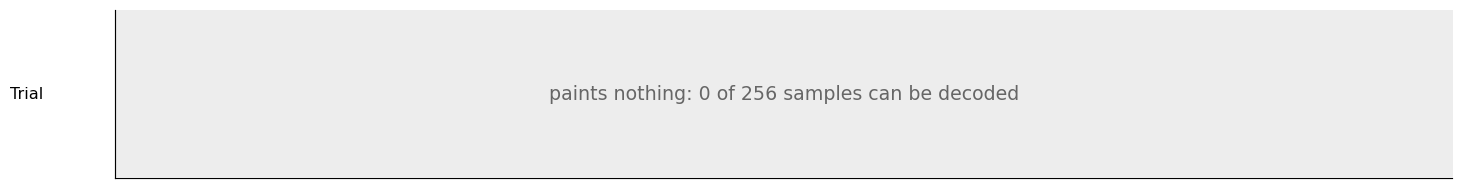

In [2]:
sh = np.load(need(Path("_src/data_08/samples_run_I_cpu.npz")))
rows_sh = sh["tokens"]
secs = sh["seconds"]
se_ = json.loads(need(Path("_src/data_08/samples_run_I_cpu_eye.json")).read_text())


def first_n_strokes(stages, n):
    '''The first n strokes in painting order (what is on the canvas after n strokes).'''
    out, left = [], n
    for st in stages:
        take = min(left, len(st["alpha"]))
        if take:
            out.append({k: v[:take] for k, v in st.items()})
        left -= take
        if left <= 0:
            break
    return out


def render_n(row, n):
    if n == 0:
        return np.ones((B.SIDE, B.SIDE, 3))
    return T.render(first_n_strokes(T.decode(G.strokes_only(row).tolist()), n)).clip(0, 1)


def valid_strokes_only(row):
    '''A sample that cannot be decoded completely: draw only the strokes whose five tokens all fall in the correct
    field. Returns (painting, share of strokes skipped).'''
    import torch
    ok = G.valid(row[None])[0]
    _, _, slot = G.layout_of(row[None])
    xs = np.flatnonzero(slot == 1 + G.FIELDS.index("x"))                 # position of each stroke's first token
    idx = xs[:, None] + np.arange(T.TOKENS_PER_STROKE)
    good = ok[idx].all(1)
    stage_of = np.repeat(np.arange(len(G.STROKES)), G.STROKES)
    ys_, xs_ = torch.meshgrid(torch.arange(B.SIDE) + 0.5, torch.arange(B.SIDE) + 0.5, indexing="ij")
    grid, canvas = torch.stack([xs_, ys_], -1), torch.ones(B.SIDE, B.SIDE, 3)
    with torch.no_grad():
        for k in range(len(G.STROKES)):
            sel = (stage_of == k) & good
            if sel.any():
                st = T.stroke_params(row[idx[sel]], k)
                canvas = B.composite(canvas, B.Strokes.from_stage(st, B.STAGES[k][:2]), grid)
    return canvas.numpy().clip(0, 1), 1 - good.mean()


def fig1_row(n, label_, why=""):
    '''One row of Figure 1: the first 8 samples run n drew during evaluation (the first row of samples.png). For a
    version whose samples cannot be decoded completely, the first 8 are drawn from the saved tokens
    (samples64_tokens.npz, same seed and batch as the evaluation), with only the strokes whose five tokens all fall in
    the correct field, and the share of skipped strokes below each painting. Without either, the reason why is shown.'''
    f_ = RUNS / n / "samples.png" if n else None
    z_ = RUNS / n / "samples64_tokens.npz" if n else None
    _, a = plt.subplots(figsize=(14, 1.95))
    if f_ is not None and f_.exists():
        a.imshow(Image.open(need(f_)).convert("RGB").crop((0, 0, 2048, 256)))
    elif z_ is not None and z_.exists():
        drawn = [valid_strokes_only(r) for r in np.load(need(z_))["tokens"][:8]]
        a.imshow(np.concatenate([im for im, _ in drawn], 1))
        for i, (_, drop) in enumerate(drawn):
            a.text(256 * i + 128, 250, f"{drop:.0%} of strokes skipped", ha="center", va="bottom", fontsize=9,
                   color="white", bbox=dict(facecolor="black", alpha=0.6, pad=1.5, lw=0))
    else:
        a.imshow(np.full((256, 2048, 3), 0.93))
        a.text(1024, 128, why, ha="center", va="center", fontsize=13, color="0.4")
    a.set_xticks([])
    a.set_yticks([])
    a.grid(False)
    a.set_ylabel(label_, rotation=0, labelpad=60, fontsize=11, va="center")
    plt.tight_layout()
    plt.show()


fig1_row(None, "Trial", "paints nothing: 0 of 256 samples can be decoded")

**Trial**: best step 500, validation loss 4.296 (82 validation cats).
Achieved: the painter, tokenisation, training and sampling ran from end to end for the first time, and the validation
loss fell as training cats were added (4.469 with 400 cats, 4.296 with 809).
Still lacking: about 15% of tokens fall in the wrong field, and not a single painting can be drawn (Appendix A).

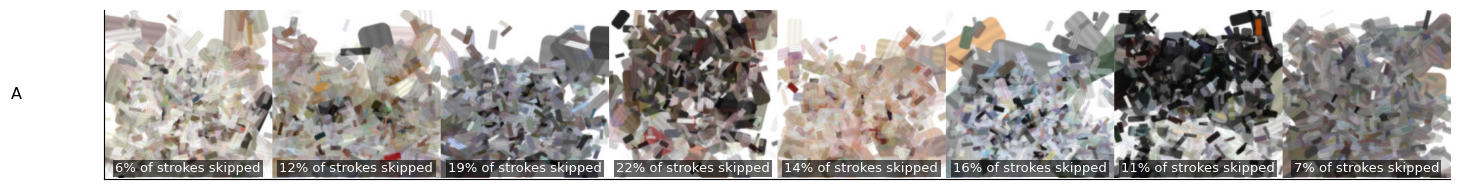

In [3]:
fig1_row("A_list", "A", "paints nothing: 0 of 256 samples can be decoded")

**A**: best step 1,000, training loss 4.181, validation loss 4.230 (153 validation cats); afterwards the training loss
keeps falling while the validation loss rises, and training stops early at step 1,600.
The validation loss of the next stroke's `x` position is 5.50, almost equal to the 5.55 (ln 256) of uniform guessing,
as in the trial.
The row above shows the first eight samples drawn again with the same seed and batch size as the evaluation: since none
of them can be decoded completely, only the strokes whose five tokens all fall in the correct field are drawn, and the
share of skipped strokes is written below each painting.
Achieved: the trial's settings are reproduced with 1,639 training cats, which confirms that the problem is not too few
training cats.
Still lacking: 0 of 256 samples can be decoded completely, and 17.1% of tokens fall in the wrong field; even the valid
strokes form only scattered patches of colour with no recognisable cat shape. More training cats alone cannot solve
the problems of stroke order and fields.

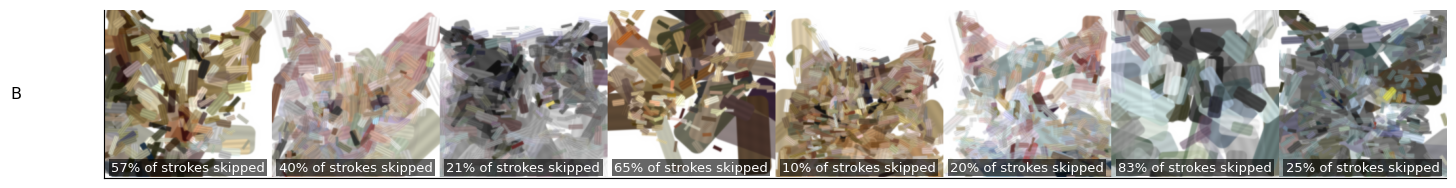

In [4]:
fig1_row("B_overlap", "B", "paints nothing: 0 of 256 samples can be decoded")

**B**: best step 2,000, training loss 3.908, validation loss 4.054 (153 validation cats); training stops early at step
2,600.
The validation loss of the next stroke's `x` position falls from A's 5.50 to 4.65, almost the same as C's 4.66: the
overlap order makes the position of the next stroke predictable. The row above is drawn in the same way as A's.
Achieved: the position can now be learned, and the validation loss is clearly lower than A's.
Still lacking: 0 of 256 samples can be decoded completely, and the share of tokens in the wrong field even rises to
53.4% (A: 17.1%). Errors accumulate: every one of the 64 resampled paintings goes wrong at least once, after the first
error an average of 61% of tokens fall in the wrong field (A: 20%), and later stages are worse (in stage 4 only 40% of
strokes have all five tokens valid). Changing the stroke order alone is not enough; the field restriction (C) is also
needed.

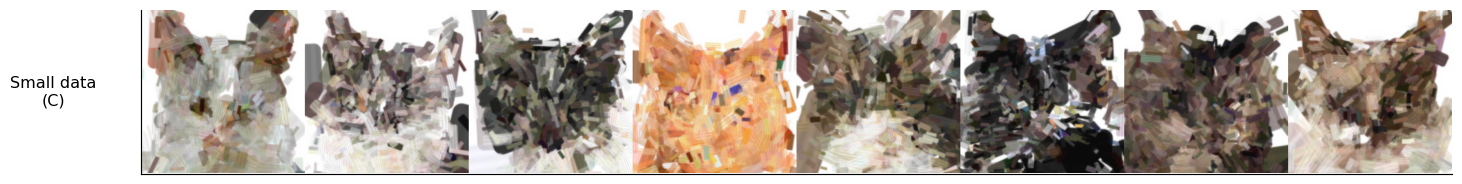

In [5]:
fig1_row("C_overlap_heads", "Small data\n(C)")

**Small data (C)**: best step 1,600, training loss 3.927, validation loss 4.042 (153 validation cats).
Achieved: with "each field chooses only among its own tokens", it paints complete pictures for the first time: all 256
samples can be decoded, and the fur colour and rough head shape are visible.
Still lacking: trained on only 1,639 cats, the facial structure is blurred, no eyes can be seen, and the strokes are
messy.

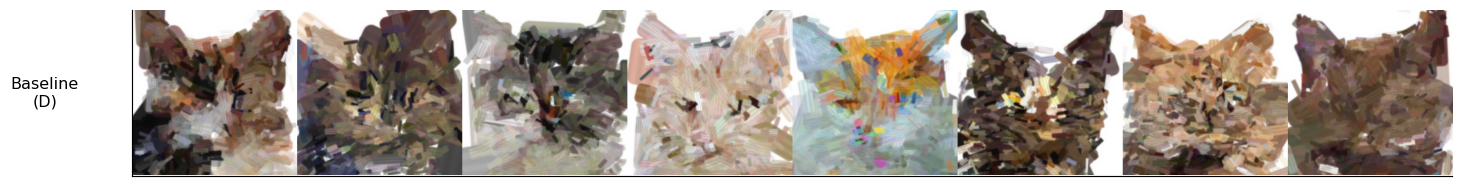

In [6]:
fig1_row("D_all_cats", "Baseline\n(D)")

**Baseline (D)**: best step 2,900, training loss 3.882, validation loss 3.933 (292 validation cats); eye ratio 0.84,
FID 209.
Achieved: with twice as many training cats, almost every painting has two ears and a head shape, the fur has the
colours of real cats, and nothing is copied from the training data.
Still lacking: the eyes are only dark blobs; an FID of 209 is far from that of real paintings (about 39); overfitting
starts after 6–8 epochs.

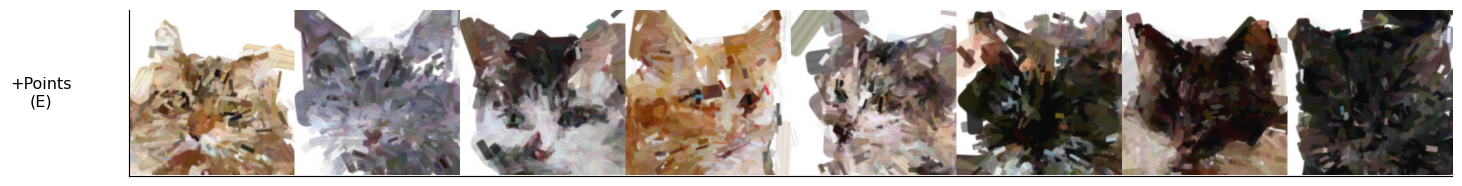

In [7]:
fig1_row("E_points", "+Points\n(E)")

**+Points (E)**: best step 2,900, training loss 3.867, validation loss 3.917; eye ratio 0.87, FID 209.
Achieved: the model decides the positions of the nine face points before it starts painting. Still lacking: the gain
in eye score is within the noise, and the pictures change little.

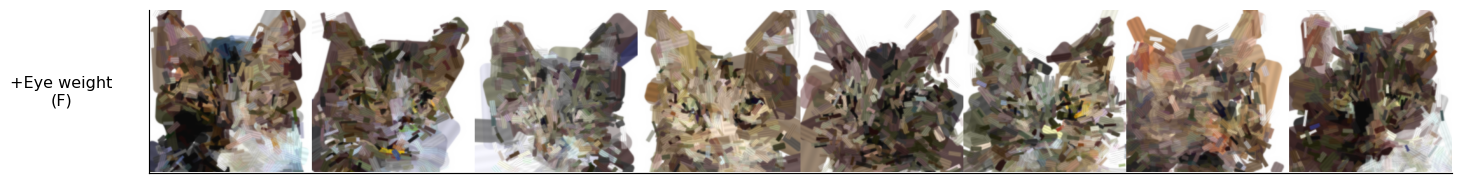

In [8]:
fig1_row("F_eye_weight", "+Eye weight\n(F)")

**+Eye weight (F)**: best step 2,900, training loss 3.889 (weighted), validation loss 3.961; eye ratio 0.87, FID 232.
Achieved: the loss of the strokes around the eyes falls. Still lacking: everything else gets worse (FID 232, a
validation loss 0.028 higher than the baseline's), so on its own it does not help.

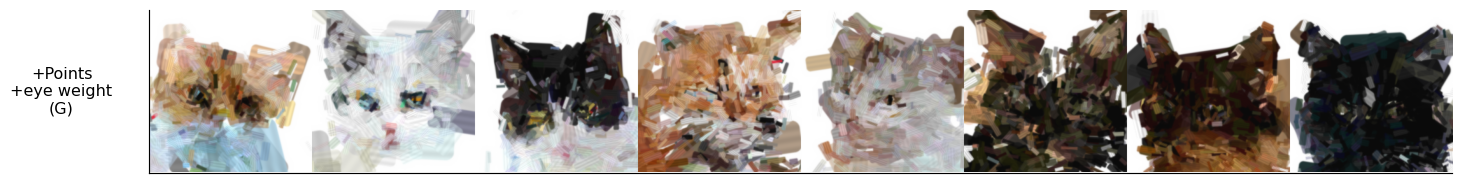

In [9]:
fig1_row("G_points_eyes", "+Points\n+eye weight\n(G)")

**+Points +eye weight (G)**: best step 3,400, training loss 3.824 (weighted), validation loss 3.947; eye ratio 0.90,
FID 229.
Achieved: combined, the two give an eye score clearly above the baseline's for the first time (by more than 3
standard errors), and eyes start to appear in a few paintings. Still lacking: the FID (229) is still worse than the
baseline's, and most paintings still have no clear eyes.

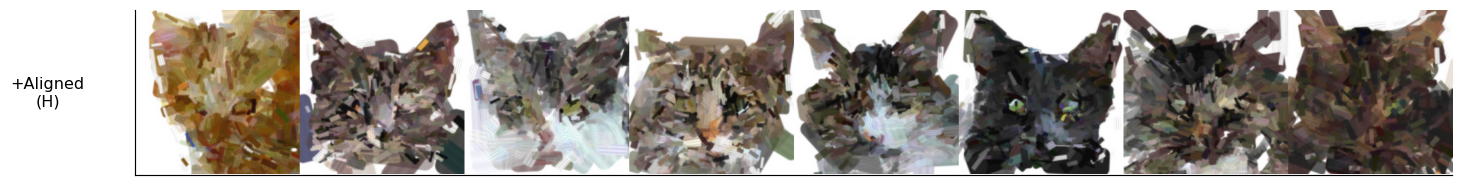

In [10]:
fig1_row("H_aligned", "+Aligned\n(H)")

**+Aligned (H)**: best step 2,900, training loss 3.818, validation loss 3.886 (the validation paintings are aligned as
well); eye ratio 0.89, FID 194.
Achieved: the face is centred and the FID falls to 194, without repainting any data. Still lacking: the eyes are still
unclear.

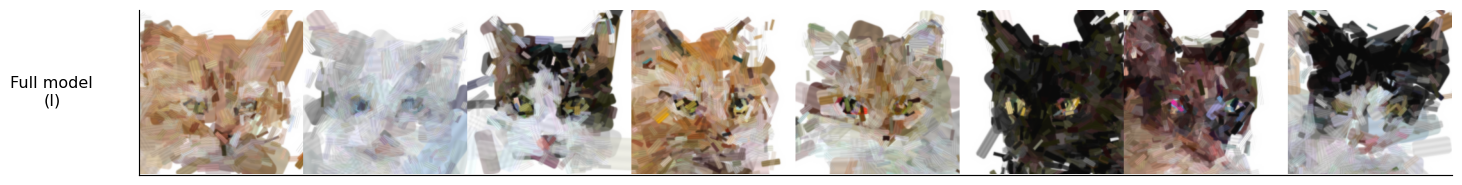

In [11]:
fig1_row("I_aligned_points_eyes", "Full model\n(I)")

**Full model (I)**: best step 2,500, training loss 3.830 (weighted), validation loss 3.915; eye ratio 0.91, FID 182.
Achieved: best on all four measures; most paintings have two correctly placed eyes, often with yellow-green irises and
dark pupils, and a few show a nose and mouth.
Still lacking: the FID against held-out test paintings is 196, against only 49 for real paintings, so the two
distributions are still far apart; light, low-contrast cats are still blurred; the eyes are spoiled mainly in the two
finest stages (Section 8.5); and the face points written first are used only slightly (Section 5.5).

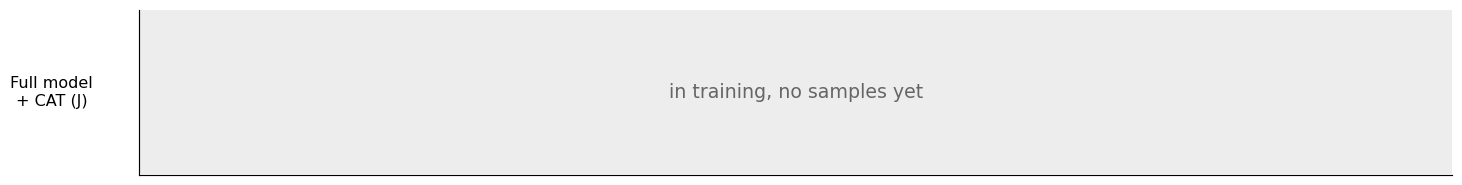

In [12]:
fig1_row("J_cat_aligned_points_eyes", "Full model\n+ CAT (J)", "in training, no samples yet")

**Full model + CAT (J)**: in training; at the time of writing the best is step 6,300, with training loss 3.730
(weighted) and validation loss 3.804 (813 validation cats; the Full model scores 3.933 on the same validation set).
Goal: to reduce overfitting with more cats from the same distribution, with all other settings as in the Full model.
Samples and evaluation will be added when training finishes.

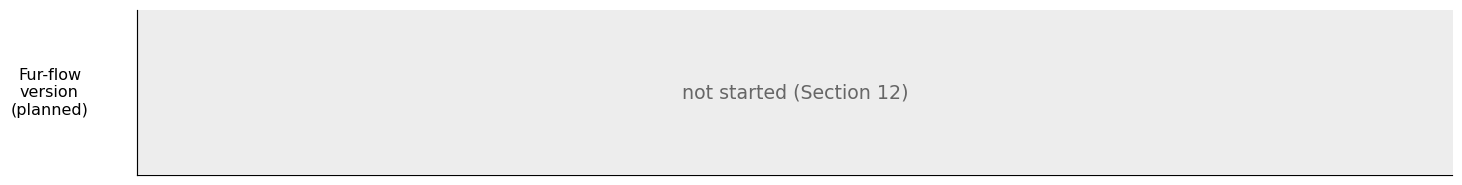

In [13]:
fig1_row(None, "Fur-flow\nversion\n(planned)", "not started (Section 12)")

**Fur-flow version (planned)**: Goal: to paint following the real oil-painting process, with the fur strokes running
along the direction of hair growth; the painter's prototype is in Section 12.4, and the model has not been trained yet.

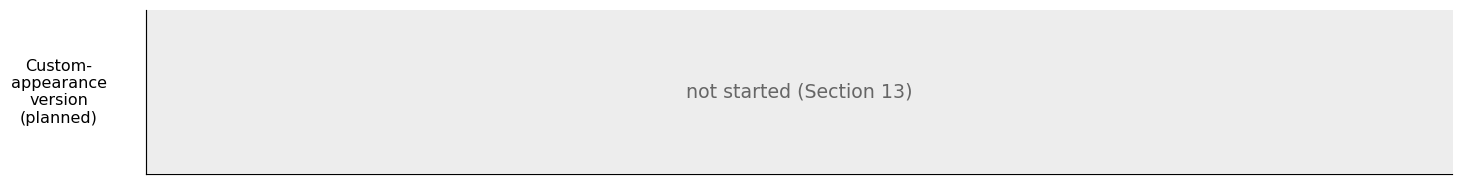

In [14]:
fig1_row(None, "Custom-\nappearance\nversion\n(planned)", "not started (Section 13)")

**Custom-appearance version (planned)**: Goal: to paint the appearance the user specifies, and when the user changes
one detail, to repaint only the affected region; the appearance-attribute reader is finished (Section 13.7), and the
conditional model is not yet implemented.

Section 8.1 compares the versions quantitatively.

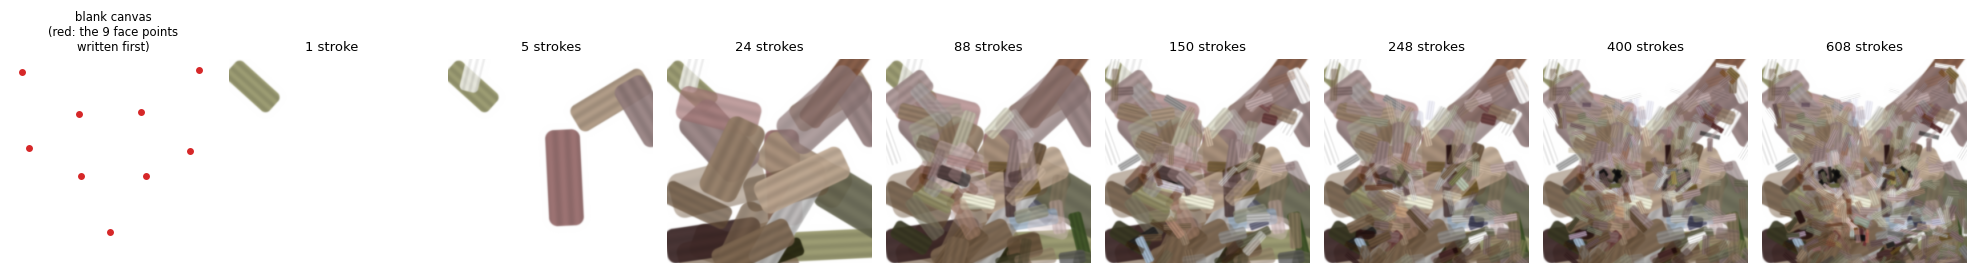

Figure 2 sampling: model I_aligned_points_eyes, seed 0, device cpu, 8 cats; 3063 tokens per cat
seconds per cat on the CPU: [12.61, 12.59, 13.21, 12.27, 15.58, 15.51, 16.21, 13.3]  mean 13.9
every token lies in the field its position allows: True
eye judge: mean 0.4828 ± 0.0214 (n = 8; the Full model's evaluation on 128 samples gives 0.488 ± 0.006)


In [15]:
counts = [0, 1, 5, 24, 88, 150, 248, 400, 608]            # 24, 88, 248 and 608 end stages 1-4
cat = 3
pts = (rows_sh[cat, 1:1 + G.PREFIX].reshape(-1, 2) - np.array([T.OFFSET["x"], T.OFFSET["y"]]) + 0.5)
fig, ax = plt.subplots(1, len(counts), figsize=(2.1 * len(counts), 2.5))
for a, n in zip(ax, counts):
    a.imshow(render_n(rows_sh[cat], n))
    a.set_title(f"{n} stroke{'' if n == 1 else 's'}", fontsize=9)
    a.axis("off")
ax[0].scatter(pts[:, 0], pts[:, 1], c="tab:red", s=14)
ax[0].set_title("blank canvas\n(red: the 9 face points\nwritten first)", fontsize=8)
plt.tight_layout()
plt.show()
print(f"Figure 2 sampling: model {sh['run']}, seed {int(sh['seed'])}, device {sh['device']}, {len(rows_sh)} cats; "
      f"{rows_sh.shape[1] - 1} tokens per cat")
print("seconds per cat on the CPU:", secs.tolist(), " mean", round(float(secs.mean()), 1))
print("every token lies in the field its position allows:", bool(G.valid(rows_sh).all()))
print(f"eye judge: mean {se_['mean']} ± {se_['se']} (n = 8; the Full model's evaluation on 128 samples gives 0.488 ± 0.006)")
_ = ver("Full model, 8 cats sampled on the CPU: mean seconds per cat / cats", (round(float(secs.mean()), 1), len(secs)),
        "_src/data_08/samples_run_I_cpu.npz", "computed here")
_ = ver("Full model, 8 cats sampled on the CPU: eye score mean ± standard error", (se_["mean"], se_["se"]),
        "_src/data_08/samples_run_I_cpu_eye.json", "computed here")

**Figure 2.** How one cat is painted: a sample drawn by the Full model (I) on a laptop CPU with seed 0, re-rendered
from its tokens after 0, 1, 5, 24, 88, 150, 248, 400 and 608 strokes. The model first writes the nine face points
(red dots, Section 6.1) and then starts painting. The first 24 strokes are broad blocks of colour (stage 1), strokes
25–88 shape the head and ears (stage 2), strokes 89–248 are where the eyes, nose and stripes usually first appear
(stage 3), and the last 360 strokes add detail (stage 4). A stroke, once laid down, is never changed; it can only be
covered by later strokes.

## 2. Related work

This section groups the work whose titles come closest to this paper into five lines of research. For each, I first
state the problem it solves in a sentence or two, then set it **side by side** with this paper in a table, and finally
explain why it cannot replace the work presented here. The column for this paper refers to the sections where each
entry is described; the other columns are taken from the cited papers themselves.

### 2.1 Reconstructing a given image with strokes (stroke-based rendering)

Methods in this line take a **target image** as input and output a set of strokes that paints it: the question they
answer is how to reproduce a given picture with strokes.

**Table 1a.** Stroke-based reconstruction methods compared with this paper.

| | **This paper (Brush GPT)** | Learning to Paint [1] | SNP [2] | Paint Transformer [3] | Intelli-Paint [4] | AttentionPainter and others [5–7] |
|---|---|---|---|---|---|---|
| Input | **None** (blank canvas) | Target image | Target image | Target image | Target image | Target image |
| Can paint a cat absent from the training data | **Yes** | No (reproduces the given image only) | No | No | No | No |
| What is learned | The distribution of stroke sequences (a generative model) | A policy that decomposes an image into strokes | Nothing; each image is optimised separately | An image-to-strokes mapping | An image-to-strokes mapping with a human-like order | Image to strokes, with better efficiency, texture or ordering |
| Who decides each stroke | The model, sampling token by token | An agent, guided by the target image | Gradient descent towards the target image | A network, from the target image | From the target image | From the target image |

**Difference.** This line answers how to reproduce a picture that already exists; this paper asks how to paint a cat
when there is no picture at all. Because the inputs differ, these methods cannot perform the task studied here. I use
this kind of technique only to **build the training data**: the painter of Section 4.1 optimises strokes directly
through a differentiable renderer (the approach of SNP) to turn training photographs into stroke sequences. It is
data preprocessing, not the generative model this paper evaluates.

### 2.2 Generating stroke sequences without a target image

This line is the closest to this paper: the model produces strokes itself instead of reproducing a given picture.

**Table 1b.** Stroke-sequence generation methods compared with this paper.

| | **This paper (Brush GPT)** | Sketch-RNN [8] | Sketchformer [9] | I-Paint [10] | PaintCopilot [11] |
|---|---|---|---|---|---|
| Needs a reference image or the current canvas | **No** | No | No | Reference photo and current canvas | Current canvas, pulled towards a target image |
| Output | **Coloured, overlapping oil-paint strokes** | Black-and-white line sketches | Black-and-white lines (a representation for classification and retrieval) | Oil-paint strokes | Strokes |
| Brush size | **Yes** (each stroke also has an opacity) | No | No | Yes | Yes |
| Coarse-to-fine stages | **4 stages, always 608 strokes** | No | No | No | No |
| Composition decided before painting | **9 face points written first** | No | No | No | Predicts a target image |
| Evaluation of structural correctness | **Independent landmark judge (eyes); errors located by stage** | Log-likelihood | Classification and retrieval accuracy | FSD, human evaluation | Behavioural checks, use by artists |

**Difference.** The only methods that paint without any reference, Sketch-RNN and Sketchformer, produce
black-and-white lines with no colour, brush or overlap. The methods with colour and brushes, I-Paint and PaintCopilot,
both need a reference photo or the current canvas. **Only this paper does both: it needs no reference of any kind and
produces coloured, overlapping oil-paint strokes.** I-Paint also reorders strokes when building its data (consecutive
strokes kept close, overlapping strokes kept in their original order), a concept close to the overlap order of
Section 4.3. The two were proposed independently and pursue different goals (I-Paint seeks continuity, this paper
top-to-bottom bands), and neither compares how stroke order affects **learnability**.

### 2.3 Autoregressive generation of vector graphics from discrete tokens

This line is the closest to this paper in **representation**: graphics are discretised into tokens and a Transformer
generates them one token at a time.

**Table 1c.** Token-based vector-graphics generation compared with this paper.

| | **This paper (Brush GPT)** | IconShop [12] | StrokeNUWA [13] |
|---|---|---|---|
| What is generated | **Oil-painted cat faces** | Black-and-white vector icons | Black-and-white vector icons |
| Colour, brush size, overlap | **Yes** | No | No |
| Condition | **None** | Text (optional) | Text (required) |
| Tokens per stroke | **Always 5, each a readable field** (position, angle, size, colour) | Path commands and coordinates | Codes learned by vector quantisation (not directly readable) |
| Coarse-to-fine stages | **4 stages** | No | No |
| Model size | **27.9 million parameters; about 14 s per cat on a laptop CPU** | 12-layer decoder | 3 billion parameters (Flan-T5) |
| Evaluation | **Independent landmark judge (structure), FID, KID, diversity** | FID, Uniqueness / Novelty | FID, CLIPScore |

**Difference.** Representing graphics as discrete tokens generated autoregressively has already been done, and done
well, for vector icons (IconShop reaches an FID of 6.08 in unconditional generation); I do not claim it as new. Icons,
however, are single-colour lines without brushes or overlap. Every oil-paint stroke also carries a colour, a size and
an opacity, and later strokes cover earlier ones, so the sequences are longer (3,064 tokens), the fields differ more in
nature, and stroke order directly determines the picture (Section 1.2). These are exactly the problems that icons do
not pose and that this paper addresses.

### 2.4 Generating the painting process as pixel video

This line also generates the process from a blank canvas to a finished picture, but its output is pixel frames.

**Table 1d.** Painting-process video generation compared with this paper.

| | **This paper (Brush GPT)** | ProcessPainter [14] | PaintsAlter [15] | Inverse Painting [16] | Loomis Painter [17] |
|---|---|---|---|---|---|
| Required input | **None** | Text | A canvas | A finished painting | An image |
| Output | **Stroke parameters (each stroke can be edited or removed on its own)** | 8 pixel frames | Earlier or later pixel canvases | A pixel time-lapse | A pixel video |
| Granularity of the process | **608 strokes** | 8 frames | — | One semantic region at a time | Video frames |
| Model and compute | **27.9 million parameters; 8–16 minutes of training on one A100** | Stable Diffusion + AnimateDiff | Video diffusion model; 4–9 days on 8 H100s | LLaVA + a diffusion model | 14-billion-parameter video model; 24 hours on 4 H100s |

**Difference.** Video models produce pixels that look like painting in progress, but there is no stroke in them that
can be taken out and changed. The output of this paper is the strokes themselves, so the process can be replayed,
and each stroke edited or removed, one at a time; this is also what makes the local repainting of Section 13
possible. The model is also far smaller, about 500 times smaller than the 14 billion parameters of Loomis Painter.
Two observations from this line are relevant here: Inverse Painting treats the order of painting one semantic region
at a time as something to be learned, and Loomis Painter finds that training on frames in reverse order works better,
showing that **order affects learnability**.

### 2.5 Stroke direction: from image orientation fields to fur flow

Which way a stroke should point has a long history in stroke-based rendering. The painter of Section 4.1 belongs to
the family that takes direction from the image; the oil-process painter of Section 12 instead derives fur flow from
an animal's facial keypoints.

**Table 1e.** Where stroke direction comes from: existing methods and Section 12 of this paper.

| | **This paper, Section 12** | Litwinowicz [32], Hertzmann [33] | Hays and Essa [34], Im2Oil [43] | Wagner et al. [36] | Zhao and Zhu [38], Wang et al. [37] | AutoHair [40], NeuralFur [41] |
|---|---|---|---|---|---|---|
| Source of direction | **Facial keypoints + rules of fur growth** (refined by image texture) | Image gradients | Strong edges (interpolated with radial basis functions, or the edge tangent flow of Kang et al. [53]) | Local image orientation (facial points only decide where detail strokes go) | Facial landmarks + contours and image edges | Learned growth direction of hair or fur |
| Subject | **Animal (cat) faces** | Any photograph | Any photograph | Portraits | Portraits | Human hair; animal bodies |
| Purpose | **2D stroke-based painting** | 2D stroke-based painting | 2D stroke-based painting | 2D stroke-based painting | 2D stroke-based painting | 3D reconstruction |
| Follows the direction of fur growth | **Yes** | No (follows edges) | No (follows edges) | No | No (follows contours) | Yes, but not used to place strokes |

**Difference.** In stroke-based painting, direction comes either from image edges or from the contours of human faces;
the methods that model the growth direction of hair and fur do so for 3D reconstruction, not for painting strokes.
**Chaining animal facial keypoints to a fur-growth direction and then to the direction of every stroke has no
precedent in the literature I found** (Section 12.3). I do not claim that shaping an orientation field with facial
points, or modelling the growth direction of hair, is new in itself. Section 12.4 also measures that the three
image-only rules from the literature are almost unrelated to the direction of fur growth (42.5–46.3° away from it,
indistinguishable from the 45° of random directions). Other related approaches, in which Salisbury et al. [42] draw
an orientation field by hand on the photograph, Kotovenko et al. [54] let the user steer the flow of strokes with
drawn curves, and Kowalski et al. [35] suggest fur with a few tufts on a 3D model, all require a person to specify the
direction. Appendix F gives the details of each paper.

### 2.6 Positioning of this paper

**Table 1.** Comparison with the three closest works.

| | This paper | I-Paint [10] | IconShop [12] | PaintCopilot [11] |
|---|---|---|---|---|
| Condition | **None** | Reference photo + current canvas | Text (optional) | Current canvas + target image |
| Output | Coloured, overlapping oil-paint strokes | Oil-paint strokes | Black-and-white vector paths | Strokes |
| Representation of a stroke | 5 discrete tokens | 8 continuous values | Discrete coordinate tokens | 8 continuous values |
| Generation | Autoregressive (token by token) | Conditional VAE (8 strokes at a time) | Autoregressive | Autoregressive + flow matching |
| Coarse to fine | 4 stages, 608 strokes | — | — | — |
| Compositional plan | 9 face points written first | None | None | Predicts a target image |
| Structural evaluation | Independent landmark judge (eyes) | FSD, human evaluation | FID, Uniqueness / Novelty | Behavioural checks, use by artists |

This paper differs from them in two ways. First, it generates coloured, overlapping, coarse-to-fine oil-paint strokes
**fully unconditionally** and autoregressively, opening each sequence with a compositional plan. Second, its evaluation
does not stop at the distribution distance of whole images: an independent judge measures **structure**, and errors
are **located by stage**.

## 3. Data

### 3.1 Data sources

* **AFHQ** (Animal Faces-HQ) [18], cats only: 5,558 cat-face photographs of 512 × 512 pixels. The faces are large,
  sharp and consistently framed, but come with **no keypoint annotations**. I use AFHQ's own test folder as the test
  set and set aside a fixed 8% of the rest as the validation set according to a hash of the file name, so that adding
  more cats never moves a cat from one split to another.
* **The CAT dataset** [19]: 9,996 photographs of cats, each with nine hand-placed face points (both eyes, the mouth,
  and three points on each ear). The faces are smaller and more loosely framed, and the backgrounds are cluttered.

Every later step needs the face points: aligning faces (Section 6.2), finding the strokes around the eyes
(Section 6.3) and judging the eyes (Section 7.2). The CAT dataset has hand annotations and AFHQ does not, so I first
train a landmark model to label AFHQ.

### 3.2 The face landmark model (made by Claude)

The landmark model is a separate project (<https://github.com/alina0607/cat-face-landmarks>):

* **Self-supervised pre-training.** A ViT-Small encoder (patch 16, 224-px input, width 384, 12 layers) is pre-trained
  as a masked autoencoder (MAE) [20]: three quarters of the patches are hidden and reconstructed. Pre-training uses
  13,061 cat faces, including the unlabelled AFHQ cats that are to be labelled later.
* **Supervised fine-tuning.** A ViTPose-style [21] decoder turns the patch features into one heat map per point, and a
  soft-argmax (integral regression) gives each point's position. It is trained for 100 epochs on the 7,996 training
  faces of the CAT dataset (1,000 validation, 1,000 test).
* **Control.** The same setup trained from random initialisation.

**Pre-training objective.** The 224 × 224 input image is normalised with the ImageNet mean and standard deviation and
cut into $N = 14 \times 14 = 196$ patches of 16 × 16 pixels. For each image, 75% of the patches are masked at random
(49 are kept); the mask $m_n = 1$ marks patch $n$ as masked. The reconstruction target is the pixels of **each patch
normalised by its own statistics** (norm-pix loss). Let $\mathbf t_n \in \mathbb R^{768}$ be the $16 \cdot 16 \cdot 3$
values of patch $n$, flattened:

$$
\hat{\mathbf t}_n = \frac{\mathbf t_n - \operatorname{mean}(\mathbf t_n)}{\sqrt{\operatorname{var}(\mathbf t_n) + 10^{-6}}},\qquad
\mathcal L_\text{MAE} = \frac{\sum_{b}\sum_{n} m_{bn}\,\tfrac{1}{768}\,\bigl\Vert \mathbf r_{bn} - \hat{\mathbf t}_{bn}\bigr\Vert _2^2}{\sum_b\sum_n m_{bn}},
$$

where $\mathbf r_{bn}$ is the decoder's (width 256, 4 layers) reconstruction of patch $n$ of image $b$ in the batch.
The loss is computed **on masked patches only**. Training images are random crops (25–100% of the area) and mirror
images from the CAT and AFHQ training sets; the held-out set is the CAT validation set and the AFHQ test set. Training
runs for 300 epochs.

**From heat maps to coordinates.** The decoder upsamples the 14 × 14 features to 56 × 56 with two transposed
convolutions and outputs $K = 9$ heat maps $H_k$ with a 1 × 1 convolution (stride $s = 4$ pixels). Each map is
normalised with a softmax over all $56 \times 56 = 3{,}136$ cells, and the position is its expectation (soft-argmax,
also called integral regression), with no temperature parameter:

$$
P_k(i,j) = \frac{\exp H_k(i,j)}{\sum_{i',j'} \exp H_k(i',j')},\qquad
\hat{\mathbf p}_k = \sum_{i,j} P_k(i,j)\,\bigl((j+\tfrac12)s - \tfrac12,\ (i+\tfrac12)s - \tfrac12\bigr).
$$

The fine-tuning loss is the Euclidean distance between predicted and true points (not squared, in pixels of the
224-px input), counting only points whose true position lies inside the input ($v_{bk} = 1$):

$$
\mathcal L_\text{pose} = \frac{\sum_{b,k} v_{bk}\,\Vert \hat{\mathbf p}_{bk} - \mathbf p_{bk}\Vert _2}{\max\bigl(1, \sum_{b,k} v_{bk}\bigr)}.
$$

**Evaluation metrics.** Errors are normalised by the true distance between the eyes,
$d_b = \Vert \mathbf p_{b0} - \mathbf p_{b1}\Vert $ (the CAT dataset has one point per eye, so this is the distance
between the eye centres):

$$
\mathrm{NME}_b = \frac{1}{9}\sum_{k=0}^{8} \frac{\Vert \hat{\mathbf p}_{bk} - \mathbf p_{bk}\Vert }{d_b},\qquad
\mathrm{NME} = \frac{1}{B}\sum_b \mathrm{NME}_b,\qquad
\text{failure rate} = \frac{1}{B}\sum_b \mathbb 1[\mathrm{NME}_b > 0.1].
$$

All nine points are counted in evaluation (the training-time mask for points inside the input is not applied). The
model's **confidence** in point $k$ is the largest probability after the softmax,
$\kappa_k = \max_{i,j} P_k(i,j) \in (1/3136,\ 1]$; the eye judge of Section 7.2 uses this quantity.

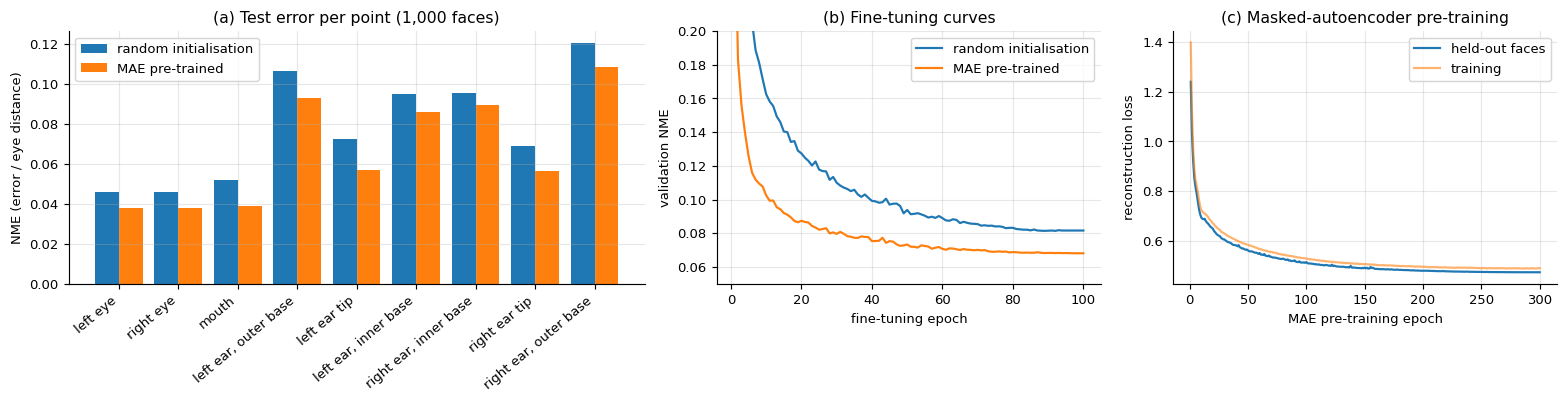

test NME / failure rate: {'pose_scratch': (0.078, 0.214), 'pose_mae': (0.067, 0.122)}
best validation NME: {'pose_scratch': 0.0814, 'pose_mae': 0.0681}


In [4]:
res = {n: json.loads(need(LAND / f"runs/{n}/eval_test.json").read_text()) for n in ("pose_scratch", "pose_mae")}
lm = list(res["pose_mae"]["nme_per_landmark"])
curves = {n: jl(LAND / f"runs/{n}/metrics.jsonl") for n in ("pose_scratch", "pose_mae")}
mae = jl(LAND / "runs/mae/metrics.jsonl")
LMEN = {"left_eye": "left eye", "right_eye": "right eye", "mouth": "mouth", "left_ear_outer": "left ear, outer base",
        "left_ear_tip": "left ear tip", "left_ear_inner": "left ear, inner base", "right_ear_inner": "right ear, inner base",
        "right_ear_tip": "right ear tip", "right_ear_outer": "right ear, outer base"}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1.5, 1, 1]})
x, w = np.arange(9), 0.4
ax[0].bar(x - w / 2, [res["pose_scratch"]["nme_per_landmark"][k] for k in lm], w, label="random initialisation")
ax[0].bar(x + w / 2, [res["pose_mae"]["nme_per_landmark"][k] for k in lm], w, label="MAE pre-trained")
ax[0].set_xticks(x)
ax[0].set_xticklabels([LMEN.get(k, k) for k in lm], rotation=40, ha="right")
ax[0].set(ylabel="NME (error / eye distance)", title="(a) Test error per point (1,000 faces)")
ax[0].legend()
for n, lab_ in (("pose_scratch", "random initialisation"), ("pose_mae", "MAE pre-trained")):
    ax[1].plot([r["epoch"] for r in curves[n]], [r["val_nme"] for r in curves[n]], label=lab_)
ax[1].set(ylim=(0.05, 0.2), xlabel="fine-tuning epoch", ylabel="validation NME", title="(b) Fine-tuning curves")
ax[1].legend()
ax[2].plot([r["epoch"] for r in mae], [r["held_out"] for r in mae], label="held-out faces")
ax[2].plot([r["epoch"] for r in mae], [r["loss"] for r in mae], label="training", alpha=0.6)
ax[2].set(xlabel="MAE pre-training epoch", ylabel="reconstruction loss", title="(c) Masked-autoencoder pre-training")
ax[2].legend()
plt.tight_layout()
plt.show()

for n in res:
    r = res[n]
    ver(f"landmark model {n}: test NME / failure rate (NME > 0.1)", (r["nme"], r["failure_rate_0.1"]),
        f"cat-face-landmarks/runs/{n}/eval_test.json", "computed here")
ver("MAE held-out loss, epoch 1 -> 300", (mae[0]["held_out"], mae[-1]["held_out"]), "cat-face-landmarks/runs/mae/metrics.jsonl", "computed here")
print("test NME / failure rate:", {n: (res[n]["nme"], res[n]["failure_rate_0.1"]) for n in res})
print("best validation NME:", {n: min(r["val_nme"] for r in c) for n, c in curves.items()})

**Figure 3.** The landmark model. (a) Normalised mean error on the test set for each point (NME: distance to the true
point divided by the distance between the eyes); (b) fine-tuning curves for the two initialisations; (c) loss of the
masked-autoencoder pre-training. Each ear has three points: outer base, tip and inner base.

Pre-training lowers the test NME from 0.0780 to 0.0670 and the failure rate (NME > 0.1) from 21.4% to 12.2%. Every
point improves, the eyes (0.046 → 0.038) and the mouth (0.052 → 0.039) most clearly. The ear bases remain the hardest
points (0.09–0.11), consistent with the suspicion that their hand annotations are themselves less consistent. The eyes
are the points the model locates most accurately, which is the premise for using it as the eye judge in Section 7.2.

**A result that contradicts the prior expectation.** Before training I expected pre-training to help the ear bases
most, since they have no edge of their own to find and depend most on the context of the whole face. In fact, the
largest gains were on points with clear edges, such as the eyes and the mouth (development log, 2026-10-10 §1). The
expectation and the result are recorded side by side, without a post-hoc explanation.

### 3.3 Labelling and filtering AFHQ

AFHQ's crops are much tighter than the CAT faces used in training: the face nearly fills the frame, and a soft-argmax
can never place a point outside its input. Labelling the photographs directly put the tips of cut-off ears in the
corners of the image. I therefore shrink each photograph into the centre of a frame (the face covers 1/1.5 of the
input, as in training; after normalisation the frame is 0, i.e. the ImageNet mean colour, about RGB 124, 116, 104) and
map the predictions back to the photograph's coordinates, so that points can fall outside the photograph. All 5,558
AFHQ cats are labelled this way. Specifically, a photograph of side $S = 512$ is resized to 224 and then to
$\text{inner} = \operatorname{round}(224/1.5) = 149$, and pasted at offset $a = \lfloor (224-149)/2 \rfloor = 37$. A
prediction $p$ on the 224-px input is mapped back to photograph coordinates by (the same for both axes, with pixel
centres at integer coordinates)

$$
u = (p + \tfrac12 - a)\,\frac{S}{\text{inner}} - \tfrac12 = (p - 36.5)\cdot\frac{512}{149} - \tfrac12 ,
$$

so predictions with $p < 37$ or $p > 186$ fall outside the photograph, and the tip of a cut-off ear can be placed where
it really is. This fix is `label run --pad 1.5` in `cat-face-landmarks` (commit `d6e00d0`). Before it was applied to
real data, the labelling tool was tested with a fake model that places every point at the corners of the input; the
coordinates mapped back to the photograph matched a hand calculation. The first version of the labels (from the
randomly initialised model, without the frame) put many ear tips in the corners of the photograph, which is why the
frame was added.

AFHQ cats labelled: 5558
ear tip outside the photograph by more than (eye distances) -> share of cats
      0:  36.5% (2029 cats)
   0.05:  28.8% (1599 cats)
    0.1:  22.4% (1245 cats)
    0.2:  14.2% (790 cats)
    0.3:   8.3% (459 cats)


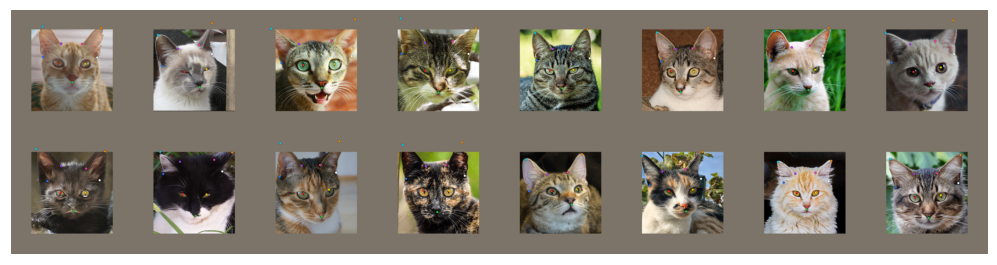

In [5]:
chk = np.load(need(ML / "data/processed/afhq_cats_mae_pad1.5_checks.npz"))
lab = np.load(need(ML / "data/processed/afhq_cats_mae_pad1.5.npz"))
tip = chk["tip_outside"]                                    # how far the outermost ear tip lies outside, in eye distances
rows = [(t, float((tip > t).mean())) for t in (0, 0.05, 0.1, 0.2, 0.3)]
print("AFHQ cats labelled:", len(lab["ids"]))
print("ear tip outside the photograph by more than (eye distances) -> share of cats")
for t, s in rows:
    print(f"   {t:>4}: {s:6.1%} ({int((tip > t).sum())} cats)")
ver("AFHQ cats labelled (MAE, pad 1.5)", len(lab["ids"]), "ml/data/processed/afhq_cats_mae_pad1.5.npz", "computed here")
ver("cats with an ear tip outside the photograph (> 0 / > 0.1 eye distances)", (round(rows[0][1], 3), round(rows[2][1], 3)),
    "ml/data/processed/afhq_cats_mae_pad1.5_checks.npz", "computed here")
show(LAND / "runs/afhq_tips_outside.png", figsize=(12, 3.2))

**Figure 4.** AFHQ cats whose ear tip lies outside the photograph (the grey frame is outside the photograph; the
points are drawn on top). 36.5% of the cats have at least one ear tip outside the photograph, and 22.4% by more than
0.1 eye distances; these tips do belong to ears cut off by the top edge.

**Filtering rules.** The generative model's **training data** are filtered by two objective rules (the generative
model's outputs are never filtered). "Uncertain labels" needs a signal that tracks the real error, so I first compared
how well candidate signals predict failure on the CAT validation set (1,000 faces), where the true points are known:

**Table 2.** AUROC of candidate signals for predicting landmark failure (NME > 0.1).

| Signal | AUROC | Note |
|---|---|---|
| Mean heat-map peak (the model's "confidence") | 0.567 | barely better than chance |
| Lowest peak | 0.606 | |
| Peaks on the eyes and mouth | 0.471 | worse than chance |
| **Mirror disagreement** | **0.825** | correlation 0.661 with the error |

Mirror disagreement is defined as follows: predict a face and its left-right mirror image, swap left and right back,
and take the mean distance between the two predictions divided by the eye distance. Formally, let
$\hat{\mathbf p}_k$ be the prediction on the framed input and $\hat{\mathbf q}_k$ the prediction on its horizontal
mirror; swapping left and right with $\pi = (1, 0, 2, 8, 7, 6, 5, 4, 3)$ and flipping the x coordinate back
($x \leftarrow 223 - x$) gives

$$
\mu_k = \frac{\bigl\Vert \hat{\mathbf p}_k - \hat{\mathbf q}_{\pi(k)}\bigr\Vert }{\Vert \hat{\mathbf p}_0 - \hat{\mathbf p}_1\Vert },\qquad
\bar\mu = \frac{1}{7}\sum_{k \notin \{4, 7\}} \mu_k .
$$

The denominator is the **predicted** eye distance (AFHQ has no true points), and $\bar\mu$ excludes the two ear tips
($k = 4, 7$). How far an ear tip lies outside the photograph is measured in the $L_\infty$ sense:

$$
\tau = \max_{k \in \{4,7\}}\ \max_{c \in \{x,y\}}\ \frac{\max\bigl(-u_{kc},\ u_{kc} - 511,\ 0\bigr)}{\Vert \mathbf u_0 - \mathbf u_1\Vert },
$$

where $\mathbf u_k$ are the points mapped back to the 512-px photograph. The AUROC in Table 2 is computed with the
Mann–Whitney rank formula,
$\mathrm{AUROC} = \bigl(\sum_{i \in \text{failures}} R_i - n_1(n_1+1)/2\bigr) / (n_1 n_0)$, where $R_i$ is the rank of
the score (confidence-type signals use $-\kappa$ as the score). The model's confidence is almost unrelated to its
errors, but how much it disagrees with itself is strongly related to them. Two rules follow:

* **Rule A:** an ear tip lies more than 0.1 eye distances outside the photograph (the ear is cut off).
* **Rule B:** mirror disagreement is in the top 5% (ear tips excluded, since the tip of a cut-off ear is a guess
  either way). The threshold was checked on example sheets first: a 10% threshold removed many ordinary frontal cats,
  so 5% was chosen.

Together, a cat is kept if $\tau \le 0.1$ and $\bar\mu \le Q_{0.95}(\bar\mu)$, where $Q_{0.95}$ is the 95th
percentile over all 5,558 cats (linear interpolation).

**A note on reproducibility.** $\tau$ and $\mu_k$ are stored in `afhq_cats_mae_pad1.5_checks.npz`, and the AUROC
values in Table 2 are quoted from the development log. Both were computed on 2026-10-10 with an ad-hoc script that was
never committed to any repository. The formulas above are reconstructed from the record of that work; the AUROC of
0.825 and the correlation of 0.661 for mirror disagreement on the CAT validation set (whether Pearson or Spearman, and
whether with the predicted or the true eye distance) can no longer be verified and are reported as quoted numbers
only.

rule A removes 1245 cats, rule B 278, both 50; kept 4085 of 5558 (73.5%); mirror threshold (95th percentile) = 0.0633


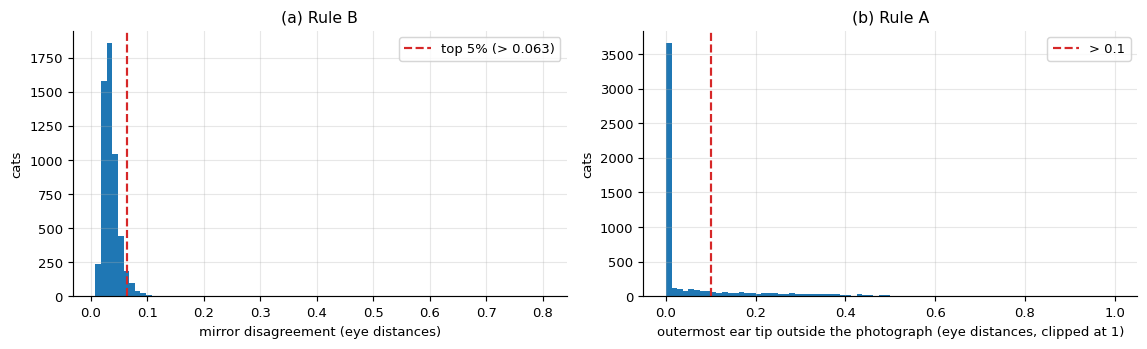

(3413, 292, 380)

In [6]:
mirror = np.delete(chk["mirror"], [4, 7], axis=1).mean(1)          # as in tools/paint_afhq.py: ear tips excluded
thr = float(np.quantile(mirror, 0.95))
A, Bm = tip > 0.1, mirror > thr
kept = ~A & ~Bm
print(f"rule A removes {int(A.sum())} cats, rule B {int(Bm.sum())}, both {int((A & Bm).sum())}; "
      f"kept {int(kept.sum())} of {len(kept)} ({kept.mean():.1%}); mirror threshold (95th percentile) = {thr:.4f}")
ver("rule A / rule B / both / kept (AFHQ, 5,558 cats)", (int(A.sum()), int(Bm.sum()), int((A & Bm).sum()), int(kept.sum())),
    "ml/data/processed/afhq_cats_mae_pad1.5_checks.npz (same formula as tools/paint_afhq.py)", "computed here")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(mirror, bins=80, color="tab:blue")
ax[0].axvline(thr, color="tab:red", ls="--", label=f"top 5% (> {thr:.3f})")
ax[0].set(xlabel="mirror disagreement (eye distances)", ylabel="cats", title="(a) Rule B")
ax[0].legend()
ax[1].hist(np.clip(tip, -0.2, 1.0), bins=80, color="tab:blue")
ax[1].axvline(0.1, color="tab:red", ls="--", label="> 0.1")
ax[1].set(xlabel="outermost ear tip outside the photograph (eye distances, clipped at 1)", ylabel="cats", title="(b) Rule A")
ax[1].legend()
plt.tight_layout()
plt.show()

z = np.load(need(TOK / "tokens_runs_DEFG.npz"))
split = Counter(z["split"].tolist())
ver("paintings in tokens_runs_DEFG.npz: train / validation / test", (split["train"], split["val"], split["test"]),
    "ml/data/processed/brushgpt/tokens_runs_DEFG.npz", "computed here")

**Figure 5.** Distributions behind the two filtering rules. (a) The threshold of rule B lies in the tail of the
distribution rather than cutting through its bulk; (b) rule A removes a long tail of cut-off ears.

The two rules remove 1,245 cats (A) and 278 cats (B), 50 of them by both, and **keep 4,085 of the 5,558 cats
(73.5%)**: 3,413 for training, 292 for validation and 380 for testing. The threshold of rule B (the 95th percentile) is
0.063 eye distances. All 4,085 kept cats were painted.

**What is not measured.** AFHQ has no hand annotations, so how well the landmark model transfers to AFHQ is not
measured directly. The landmark repository has a browser tool for hand labelling (`handlabel`, intended for 50 AFHQ
test cats), but no score file was saved in either repository, so this paper **does not report** a transfer accuracy.
The evidence that the AFHQ labels are usable is therefore indirect: the error on the CAT test set (Figure 3), and an
eye confidence of about 0.5 on real paintings when the same model serves as the judge (Section 7.2).

### 3.4 Paintings of the CAT dataset and eye-quality filtering

AFHQ's 3,413 training cats soon proved too few: every model starts to overfit after 6 to 8 epochs (Section 8.2). I
therefore painted the cats of the CAT dataset with the same painter, as additional data from the same distribution.
There are three differences from AFHQ:

* the face points are **hand-annotated**, so no landmark model is needed;
* a cat whose subject mask misses an eye is skipped before painting (otherwise the face would be painted white);
* every finished painting records four eye measures: the eye judge's score on the painting (`eye_conf`), its score on
  the photograph the painting copies (`eye_conf_photo`), how far the eyes found by the judge lie from the hand
  annotations (`eye_err`, in eye distances), and the L1 error against the photograph inside the eye discs (`eye_l1`).

,cats
painted,6983
skipped before painting: subject mask misses an eye,49
no subject mask,33
"total (CAT training list of 7,065 cats)",7065


paintings with eye measures: 6965


,5th percentile,25th percentile,50th percentile,75th percentile,95th percentile
"eye score, painting",0.3686,0.4389,0.4927,0.5474,0.6282
"eye score, photograph",0.3716,0.4417,0.4957,0.5512,0.6300
painting / photograph (per cat),0.9085,0.9662,0.9950,1.0232,1.0780
eye_err (eye distances),0.0151,0.0264,0.0378,0.0541,0.1045
eye_l1 (inside the eye discs),0.0215,0.0304,0.0391,0.0512,0.0743


,cats,share
painting score below 0.85 x photograph,73,1.0%
eyes more than 0.2 eye distances off,73,1.0%
both,11,0.2%
excluded in total (either),135,1.9%
kept,6830,98.1%


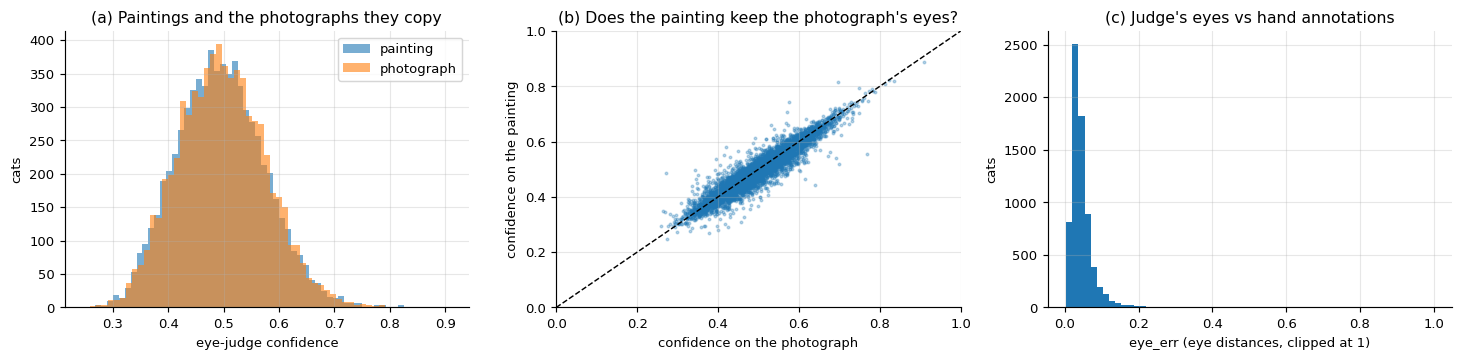

In [7]:
C = [r for r in jl(ML / "data/processed/cat_brush_face/log.jsonl") if "seconds" in r]   # log of the CAT paintings
cat_dir = ML / "data/processed/cat_brush_face"
files = sorted(cat_dir.glob("*.npz"))
listing = [str(i) for i in np.load(need(ML / "data/processed/catface/train.npz"))["ids"]]
skipped = [r for r in jl(cat_dir / "log.jsonl") if "skipped" in r]


def stem_of(full_id):
    zstem, member = full_id.split("/", 1)
    return Path(f"{zstem}__{member.replace('/', '__')}").stem


painted = {f.stem for f in files}
no_mask = [i for i in listing if not (ML / "data/raw/cat_dataset/masks" / f"{stem_of(i)}_mask1.png").exists()]
n_painted = len(painted & {stem_of(i) for i in listing})
display(pd.DataFrame({"cats": [n_painted, len(skipped), len(no_mask), n_painted + len(skipped) + len(no_mask)]},
                     index=["painted", "skipped before painting: subject mask misses an eye", "no subject mask",
                            f"total (CAT training list of {len(listing):,} cats)"]))
ver("CAT list: painted / skipped / no mask", (n_painted, len(skipped), len(no_mask)), "cat_brush_face/*.npz, log.jsonl, cat_dataset/masks", "computed here")

ok = [r for r in C if "eye_conf" in r]
conf, phot, err, el1 = (np.array([r[k] for r in ok]) for k in ("eye_conf", "eye_conf_photo", "eye_err", "eye_l1"))
print(f"paintings with eye measures: {len(ok)}")
ratio = conf / np.maximum(phot, 1e-6)
PCT = [5, 25, 50, 75, 95]
display(pd.DataFrame([np.quantile(v, [p / 100 for p in PCT]).round(4) for v in (conf, phot, ratio, err, el1)],
                     index=["eye score, painting", "eye score, photograph", "painting / photograph (per cat)",
                            "eye_err (eye distances)", "eye_l1 (inside the eye discs)"],
                     columns=[f"{p}th percentile" for p in PCT]))
low, far = conf < G.CAT_EYE_CONF_RATIO * phot, err > G.CAT_EYE_ERR
excl = {f"painting score below {G.CAT_EYE_CONF_RATIO} x photograph": int(low.sum()),
        f"eyes more than {G.CAT_EYE_ERR} eye distances off": int(far.sum()), "both": int((low & far).sum()),
        "excluded in total (either)": int((low | far).sum()), "kept": int((~(low | far)).sum())}
display(pd.DataFrame({"cats": list(excl.values()), "share": [f"{v / len(ok):.1%}" for v in excl.values()]}, index=list(excl)))
ver("CAT eye rule exclusions (low ratio / off / both / total)", (int(low.sum()), int(far.sum()), int((low & far).sum()), int((low | far).sum())),
    "cat_brush_face/log.jsonl; brushgpt.CAT_EYE_*", "computed here")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(conf, bins=60, alpha=0.6, label="painting")
ax[0].hist(phot, bins=60, alpha=0.6, label="photograph")
ax[0].set(xlabel="eye-judge confidence", ylabel="cats", title="(a) Paintings and the photographs they copy")
ax[0].legend()
ax[1].scatter(phot, conf, s=3, alpha=0.3)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlim=(0, 1), ylim=(0, 1), xlabel="confidence on the photograph", ylabel="confidence on the painting",
          title="(b) Does the painting keep the photograph's eyes?")
ax[2].hist(np.clip(err, 0, 1), bins=60)
ax[2].set(xlabel="eye_err (eye distances, clipped at 1)", ylabel="cats", title="(c) Judge's eyes vs hand annotations")
plt.tight_layout()
plt.show()

**Table 2b.** What happened to the cats of the CAT training list (number of cats). **Table 2c.** Percentiles of the
eye measures over the 6,965 CAT paintings that have them. **Table 2d.** Paintings excluded by the eye-quality rule
(described below). **Figure 6** (below the tables). Eye
quality of the 6,965 paintings of the CAT dataset. (a)(b) The eye score of a painting closely follows that of the
photograph it copies (median per-cat ratio 0.995); (c) the eyes the judge finds on a painting typically lie 0.038 eye
distances from the hand annotations (95th percentile 0.104).

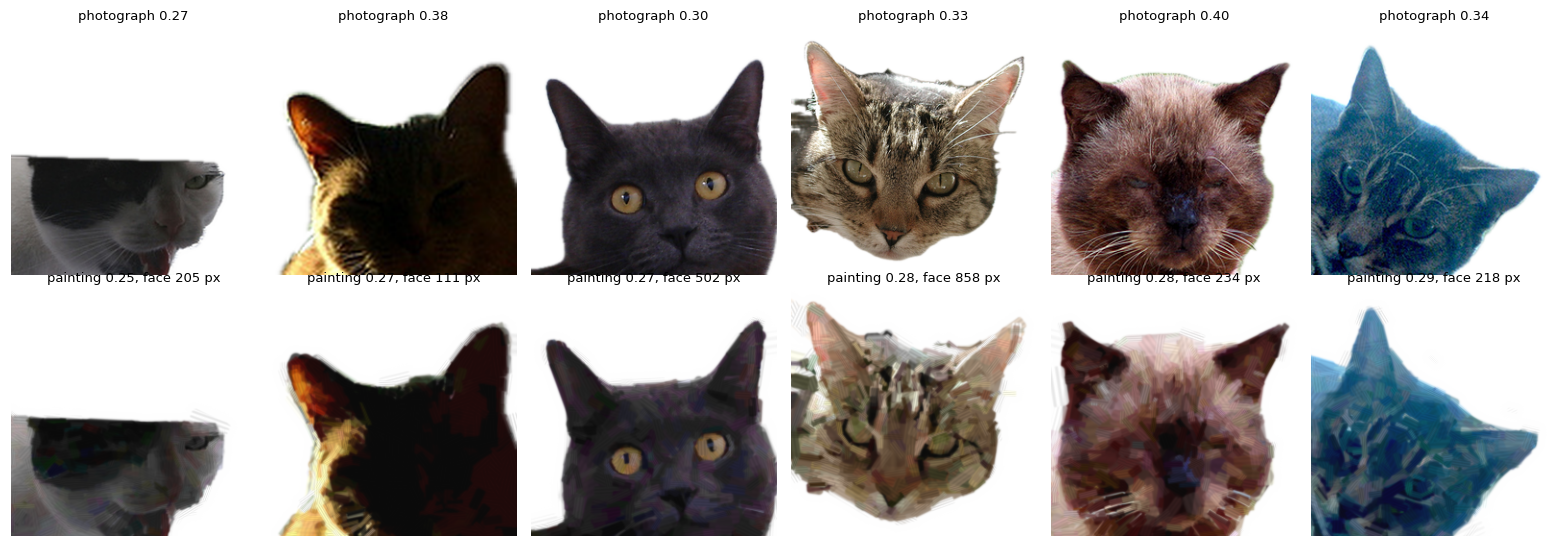

In [8]:
worst = sorted(ok, key=lambda r: r["eye_conf"])[:6]
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for j, r in enumerate(worst):
    s_ = stem_of(r["id"])
    zz = np.load(cat_dir / f"{s_}.npz")
    bx = tuple(int(v) for v in zz["box"])
    ph = B.load(str(need(ML / "data/raw/cat_dataset/photos" / f"{s_}.jpg")), str(need(ML / "data/raw/cat_dataset/masks" / f"{s_}_mask1.png")), bx).target.numpy()
    ax[0, j].imshow(ph)
    ax[1, j].imshow(T.render(T.load_npz(str(cat_dir / f"{s_}.npz"))).clip(0, 1))
    ax[0, j].set_title(f"photograph {r['eye_conf_photo']:.2f}", fontsize=9)
    ax[1, j].set_title(f"painting {r['eye_conf']:.2f}, face {r['side']} px", fontsize=9)
    ax[0, j].axis("off")
    ax[1, j].axis("off")
plt.tight_layout()
plt.show()

**Figure 7.** The six CAT cats whose paintings have the lowest eye scores (top: the photograph and its score;
bottom: the painting). Five of the six photographs also score low (0.27–0.38): a head cut off by the frame, a cat in
shadow, a head turned to one side, and two cats with clearly visible eyes that still score low, a blind spot of the
judge itself; these are not failed paintings. The fifth is different: a cat with half-closed eyes whose photograph
scores 0.40 and whose painting only 0.28, so the painting lost the eyes the photograph had. Face size is not the cause
(faces 111–858 px wide).

**Eye-quality rule.** A threshold on the painting's own score would remove hard photographs together with failed
paintings, so the rule compares each painting with **its own photograph**: a cat is left out of training if the
painting's eye score is below 0.85 times the photograph's, or if the eyes found by the judge lie more than 0.2 eye
distances from the hand annotations. The rule excludes 135 of the 6,965 paintings (1.9%), including the fifth cat in
Figure 7.

### 3.5 Data summary

In [9]:
zj = np.load(need(TOK / "tokens_J.npz"))
src = np.where(np.char.startswith(zj["ids"].astype(str), "CAT_DATASET"), "CAT", "AFHQ")
jt = {s: {d: int(((zj["split"] == s) & (src == d)).sum()) for d in ("AFHQ", "CAT")} for s in ("train", "val", "test")}
tab = pd.DataFrame(jt).T.rename(index={"train": "training", "val": "validation", "test": "test"})
tab["total"] = tab.sum(1)
display(tab)
ver("data with CAT: training AFHQ + CAT, validation AFHQ + CAT, test AFHQ", (jt["train"]["AFHQ"], jt["train"]["CAT"], jt["val"]["AFHQ"], jt["val"]["CAT"], jt["test"]["AFHQ"]),
    "ml/data/processed/brushgpt/tokens_J.npz", "computed here")

,AFHQ,CAT,total
training,3413,6327,9740
validation,292,521,813
test,380,0,380


(3413, 6327, 292, 521, 380)

**Table 3.** Data splits of the paintings (number of cats). The models of Sections 8.1–8.5 use AFHQ only (3,413 for
training, 292 for validation); the experiment of Section 8.6 adds the 6,327 training cats of the CAT dataset. The test
set is AFHQ's own test folder only, and no model uses it for early stopping or for choosing settings. During training,
every cat is also used as its left-right mirror image.

## 4. Data construction

This section turns a photograph into a sequence of tokens with a fixed layout: the painter of Section 4.1 turns the
photograph into a stroke sequence, Section 4.2 writes the strokes as tokens, and Section 4.3 reorders the strokes within
each stage without changing the picture. The model that learns these sequences is described in Section 5, and the
three structural design choices this paper compares in Section 6.

```
photograph + 9 face points
  └─► painter: differentiable rendering, 4 coarse-to-fine stages, 608 strokes (4.1)
        └─► tokenisation: 5 tokens per stroke, fixed layout (4.2)
              └─► stroke reordering within each stage, picture unchanged (4.3)
                    └─► decoder-only Transformer predicting one token at a time (Section 5)
                          + compositional plan, alignment, eye-weighted loss (Section 6)
```

### 4.1 The painter: turning a photograph into a stroke sequence (made by Claude)

The painter (`catbrush.py`) turns a training photograph into a sequence of strokes that serves as training data for
Brush GPT; it is **data preprocessing**, not the generative model this paper evaluates. It **optimises stroke
parameters directly** through a differentiable renderer (the approach of SNP [2]), uses the straight oil brush of
Paint Transformer [3], and paints in stages from large brushes to small ones. One cat is processed in five steps,
described in Sections 4.1.1–4.1.5; Table 4a lists every parameter of the painter, its value, and where the value
comes from.

1. **Preprocessing**: cut the face out of the photograph and replace the background with white paper (4.1.1).
2. **Stroke model**: which parameters describe a stroke and what it looks like on the canvas (4.1.2).
3. **Compositing and stages**: how strokes are layered and how large the brush is in each of the four stages (4.1.3).
4. **Stage-by-stage optimisation**: how each stage places its strokes and adjusts their parameters (4.1.4).
5. **Snapping**: moving the parameters onto the token grid at the end of each stage (4.1.5).

**Table 4a.** Parameters of the painter. The "Source" column distinguishes three cases: **decision** (chosen after a
comparison recorded in the project log), **derived** (fixed by a measurement in the code or by a mathematical
property), and **setting** (the painter's initial value, never tuned and never compared with alternatives).

| Parameter | Value | Meaning | Source |
|---|---|---|---|
| Canvas | 256 × 256 px | All stroke coordinates refer to this canvas | setting |
| Face box | 1.2 × the extent of the nine face points, square | The region cut from the 512-px original | decision (2026-10-10) |
| Brush shape | Straight brush (rounded rectangle) | The outline of a stroke | decision (2026-10-09) |
| Number of stages | 4 (the painter has a fifth stage, not used) | Coarse-to-fine layers | decision (token budget, Appendix B) |
| Brush and stroke count per stage | 96 × 40 px, 24 strokes; 56 × 22 px, 64; 32 × 12 px, 160; 18 × 7 px, 360 | Base brush size and number of strokes in each stage | setting |
| Range of length and width | 0.5–1.5 × the stage's brush | How much smaller or larger than the base brush a stroke may be | setting |
| Range of opacity | 0.3–1.0 | Every stroke covers at least 30% of what lies beneath | setting |
| Edge softness | 0.5 px | Coverage falls from 88% to 12% over about 2 px | derived (4.1.2) |
| Corner radius | 1/4 of the stroke width | Rounded ends of the stroke | setting |
| Bristle texture | ±6% brightness, about 3 streaks across the width | Makes a stroke look like an oil brush | setting |
| Initial direction | Structure tensor smoothed by a 9 × 9 box filter | Angle when a stroke is placed | setting |
| Initial opacity | 0.872 | Opacity when a stroke is placed | setting |
| Optimiser | Adam, learning rate 0.05, 150 steps per stage | Adjusts all parameters of one stage | setting |
| Window margin | 4 px | Coverage is computed only near the stroke | derived (4.1.3) |
| Switch to full-canvas computation | When the window is wider than 1/3 of the canvas | Choice of computation | derived (measured times) |

#### 4.1.1 Preprocessing: cutting out the face and removing the background

Each cat's face box is a square centred on the bounding box of its nine face points, with a side 1.2 times the
longer side of that bounding box; if it extends beyond the photograph it is moved inwards, and shrunk if necessary, so
that it lies entirely within the photograph. The box is cut from the 512-px **original** and resized to
$256 \times 256$. Painting only the face was chosen on 2026-10-10 after comparing it with painting the whole
photograph. A first version that cut the face from the 256-px canvas and enlarged it had no more detail on the face
than the whole photograph, so the cut was moved to the original. Note that AFHQ is already framed on the face (the box
is 410–500 of the 512 pixels), so the saving in tokens comes mainly from dropping the fifth stage, not from the
cropping.

The background is replaced with white paper using a subject mask $M \in [0,1]^{256 \times 256}$, computed by Apple
Vision's subject lifting on the Neural Engine; it failed on none of the 5,558 AFHQ cats. The target image the painter
fits is

$$
I = M \odot \text{photograph} + (1 - M),
$$

pure white outside the mask, so the painter needs to paint only the cat.

#### 4.1.2 The stroke model

**Parameters of a stroke.** Stage $k$ has $n_k$ strokes with a base brush of $L_k \times W_k$ pixels (Table 4a).
Stroke $i$ has eight values: its centre $(x_i, y_i)$, length $\ell_i$, width $w_i$, angle $\phi_i$, colour
$\mathbf c_i \in (0,1)^3$ and opacity $\alpha_i$. The optimisation acts on unconstrained real numbers that a logistic
function $\sigma$ maps to these parameters, so wherever the gradient pushes them, the parameters always stay within
their valid ranges:

$$
(x_i, y_i) = 256\,\sigma(\cdot),\quad (\ell_i, w_i) = \bigl(0.5 + \sigma(\cdot)\bigr)(L_k, W_k),\quad
\mathbf c_i = \sigma(\cdot),\quad \alpha_i = 0.3 + 0.7\,\sigma(\cdot).
$$

The angle $\phi_i$ is unconstrained; a brush is symmetric end to end, so $\phi_i$ and $\phi_i + \pi$ are the same
stroke, and the angle is taken modulo $\pi$ only at tokenisation.

**Shape of a stroke.** For a pixel centre $\mathbf p$, coordinates are first expressed along the stroke:
$u = (p_x - x_i)\cos\phi_i + (p_y - y_i)\sin\phi_i$ (along the length) and
$v = -(p_x - x_i)\sin\phi_i + (p_y - y_i)\cos\phi_i$ (across the width). The stroke is a rounded rectangle described
by a signed distance function $d_i$ (negative inside, positive outside; Quilez's box distance), with corner radius
$\rho = w_i/4$:

$$
\mathbf q = \bigl(\vert u\vert  - \max(\tfrac{\ell_i}{2} - \rho, 0),\ \vert v\vert  - (\tfrac{w_i}{2} - \rho)\bigr),\qquad
d_i(\mathbf p) = \bigl\Vert \max(\mathbf q, 0)\bigr\Vert _2 + \min\bigl(\max(q_u, q_v), 0\bigr) - \rho .
$$

**Soft edges.** Coverage is not 0 or 1 but $m_i(\mathbf p) = \sigma\bigl(-d_i(\mathbf p)/0.5\bigr)$: 0.5 on the edge,
0.88 one pixel inside and 0.12 one pixel outside. The edge must be soft for the stroke's position and size to have
gradients: with coverage of only 0 or 1, moving a stroke slightly would not change the loss continuously, and the
gradient would be zero almost everywhere. A scale of 0.5 px completes the transition within about 2 px, so the edge is
differentiable and still paints a crisp stroke boundary.

**Bristle texture.** The stroke's colour is multiplied by faint streaks across its width,
$S_i(\mathbf p) = 1 + 0.06\sin\bigl(9v/(w_i/2) + x_i\bigr)$: brightness varies by ±6%, and as $v$ goes from one side of
the stroke to the other the phase covers 18 radians, about three streaks; adding $x_i$ to the phase keeps the
streaks of neighbouring strokes out of step. The stroke's actual colour is $\operatorname{clip}(\mathbf c_i S_i, 0, 1)$.
The texture changes only the appearance and adds no parameters.

#### 4.1.3 Compositing and stages

**Compositing.** Let $a_i(\mathbf p) = \alpha_i m_i(\mathbf p)$ be how much stroke $i$ covers pixel $\mathbf p$. Later
strokes are laid over earlier ones ("over" compositing), and the strokes of stage $k$ are painted onto the canvas of
the previous stage, $C_{k-1}$ ($C_0 = \mathbf 1$, white paper):

$$
C_k = \sum_{i=1}^{n_k} a_i\,\operatorname{clip}(\mathbf c_i S_i)\prod_{j > i}(1 - a_j) \;+\; C_{k-1}\prod_{j=1}^{n_k}(1 - a_j).
$$

The first term is each stroke's colour times its own coverage and the share of it that no later stroke covers; the
second is what remains of the previous canvas after all strokes of this stage have covered it. The **order** of the
strokes is therefore part of the picture: where two strokes overlap, swapping them changes the picture (Section 4.3).

**The four stages.** Brushes go from large to small. Stage 1 has 24 strokes of 96 × 40 px (the stroke length is 37.5%
of the canvas side) and lays in blocks of colour; stage 2 has 64 strokes of 56 × 22 px and shapes the head and ears;
in stage 3, 160 strokes of 32 × 12 px, the eyes, nose and stripes usually first appear; stage 4, 360 strokes of
18 × 7 px, adds detail. Each stage has 2.25–2.7 times as many strokes as the previous one and a brush about 0.57
times as large, 608 strokes in all. The painter also has a fifth stage (600 strokes of 10 × 4 px), but it doubles
the sequence length while lowering the reconstruction error by only 0.0040, so it is not used (Appendix B).

**Computing near the stroke only.** Four pixels outside its edge, a stroke's coverage is only
$\sigma(-8) \approx 3 \times 10^{-4}$, so each stroke needs to be computed only inside a square window around its
centre with half-side $h = \lceil \sqrt{(0.75L_k)^2 + (0.75W_k)^2} + 4 \rceil$ ($0.75L_k$ is half of the maximum
length $1.5L_k$). When the window is wider than 1/3 of the canvas, opening a window for every stroke is slower than
computing the whole canvas (measured on the laptop GPU: 101-px windows 81 ms against 63 ms for the whole canvas;
61-px windows 14 ms against 152 ms). Stages 1 and 2, with windows of 165 px and 101 px, are therefore computed over
the whole canvas, and stages 3 and 4 (61 px and 39 px) stroke by stroke in windows. Both ways compute the same picture;
only the speed differs.

#### 4.1.4 Stage-by-stage optimisation

**Placing strokes.** At the start of stage $k$, the painter measures how far the canvas still is from the target:

$$
e(\mathbf p) = M(\mathbf p)\sum_{c} \bigl\vert I(\mathbf p, c) - C_{k-1}(\mathbf p, c)\bigr\vert + 10^{-6},
$$

and draws $n_k$ pixels **without replacement** with $P(\mathbf p) \propto e(\mathbf p)$ as the strokes' centres: the
further the canvas is from the target at a pixel, the more likely a stroke is placed there, and no pixel receives
two strokes. Each stroke starts at the base size, with the target's colour $I(\mathbf p)$ at its centre and an opacity
of $0.3 + 0.7\,\sigma(1.5) = 0.872$. Its initial angle is the minor-eigenvector direction of the structure tensor of
the grey image $g$ (Sobel gradients divided by 8, smoothed with a $9 \times 9$ box filter $\mathcal B$), that is,
**along the image's edges**:

$$
J = \mathcal B * \begin{pmatrix} g_x^2 & g_x g_y \\ g_x g_y & g_y^2 \end{pmatrix},\qquad
\phi_i^{(0)} = \tfrac12 \operatorname{atan2}\bigl(2J_{xy},\ J_{xx} - J_{yy}\bigr) + \tfrac{\pi}{2}.
$$

This direction is only a starting point that is then optimised along with the other parameters; it follows the
strongest edges in the image and does not necessarily follow the fur (Section 12).

**Optimisation.** Stage $k$ adjusts only its own parameters $\Theta_k$, with earlier stages fixed:

$$
\min_{\Theta_k}\ \mathcal L_k(\Theta_k) = \frac{1}{3 \cdot 256^2}\sum_{\mathbf p}\sum_{c=1}^{3}\bigl\vert C_k(\mathbf p, c; \Theta_k) - I(\mathbf p, c)\bigr\vert ,
$$

using Adam (learning rate 0.05, applied to the unconstrained values) for a fixed 150 steps, with no convergence test
and no error threshold (Appendix B). The loss itself is not masked; the mask enters only through the white-paper
target, so a stroke painted onto the background increases the loss because it is not white.

#### 4.1.5 Snapping to the token grid

At the end of each stage, the parameters are moved to the centres of the token bins ($\operatorname{bin}$ and
$\operatorname{ctr}$ of Section 4.2), and the canvas is recomputed from the snapped strokes:

$$
\Theta_k \leftarrow \operatorname{dec}\bigl(\operatorname{enc}(\Theta_k)\bigr),\qquad C_k \leftarrow C_k\bigl(\Theta_k\bigr).
$$

The next stage paints onto the **snapped** canvas, so smaller strokes repair the error that quantisation introduces,
and the final picture is **exactly** the picture the tokens describe (verified in Section 4.2). On the laptop GPU,
the four stages of one cat take about 33–35 seconds (Appendix C).

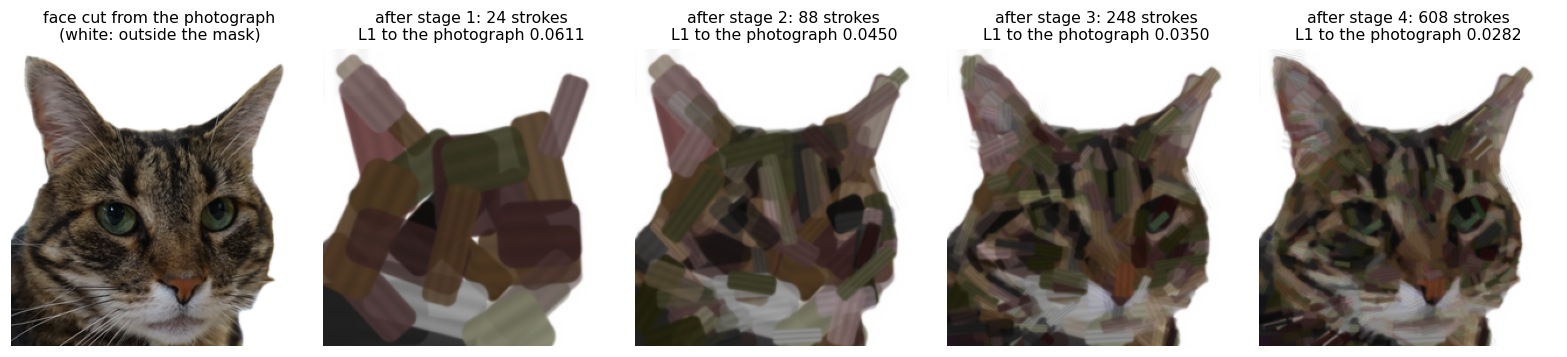

[0.0611, 0.045, 0.035, 0.0282]

In [10]:
val_ids = np.flatnonzero(z["split"] == "val")
demo = int(val_ids[0])
rel = str(z["ids"][demo])
stem = Path(rel).stem
meta = np.load(need(ML / f"data/processed/afhq_brush_face/{stem}.npz"))
box = tuple(int(v) for v in meta["box"])
photo = B.load(str(need(ML / "data/raw/afhq" / rel)), str(need(ML / f"data/processed/afhq_masks/{stem}_mask1.png")), box)
target = photo.target.numpy()
stages = T.decode(z["tokens"][demo].tolist())
frames = [T.render(stages[:k]) for k in range(1, 5)]
l1s = [float(np.abs(f - target).mean()) for f in frames]

fig, ax = plt.subplots(1, 5, figsize=(15, 3.6))
ax[0].imshow(target)
ax[0].set_title("face cut from the photograph\n(white: outside the mask)")
for k in range(4):
    ax[k + 1].imshow(frames[k].clip(0, 1))
    ax[k + 1].set_title(f"after stage {k + 1}: {sum(len(s['alpha']) for s in stages[:k + 1])} strokes\nL1 to the photograph {l1s[k]:.4f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()
ver("demonstration cat: L1 to the photograph after stages 1-4", [round(v, 4) for v in l1s], "tokens_runs_DEFG.npz + AFHQ photograph", "computed here")

**Figure 8.** A validation cat (no model was trained on it) re-rendered from its saved tokens after each of the four
stages. Each stage is a visible step: blocks of colour, head and ears, eyes and stripes, detail; the L1 error to the
photograph falls with every stage. When the painter stops (a fixed four stages, a fixed 150 steps per stage) and what
quantisation costs are discussed in Appendix B.

### 4.2 Tokenising strokes and the layout of a sequence

**Why a stroke is five tokens.** A stroke has eight values (Section 4.1.2): the centre $x$ and $y$, length, width,
angle, and the colour's R, G and B plus opacity. Writing them as tokens involves a trade-off: merging them into fewer
tokens shortens the sequence but enlarges the number of classes to choose from at each position; splitting them into
more tokens reduces the classes per position but lengthens the sequence. The cost of attention grows with the square
of the sequence length, so the sequence length directly sets the cost of training. Table 4b lists four ways to split
a stroke.

**Table 4b.** Four ways to write a stroke as tokens. Sequence length includes `BOS`, the nine face points (18
tokens), four stage markers and `EOS`; attention cost counts only the term quadratic in sequence length, relative to
this paper.

| Split | Tokens per stroke | Most classes at one position | Tokens per painting | Attention cost | Problem |
|---|---|---|---|---|---|
| One token per stroke | 1 | $5.2 \times 10^{11}$ | 632 | 0.04 | The embedding table alone would need $2.7 \times 10^{14}$ parameters, which is infeasible; learning a codebook by vector quantisation instead (as StrokeNUWA [13] does) makes tokens no longer readable as positions or colours |
| Position as one token, the rest as another | 2 | $8.0 \times 10^{6}$ | 1,240 | 0.16 | A single "angle × size × colour" token has about eight million classes, most of which never occur in data of this size |
| **One token per field (this paper)** | **5** | **6,912** | **3,064** | **1** | 3,156 classes of the colour field still never occur (Section 11) |
| One token per value | 9 | 256 | 5,496 | 3.2 | Sequence 1.8 times as long, attention cost 3.2 times as high |

I chose one token per field, for three reasons:

1. **Each token is one meaningful quantity**: a position, an angle, a size or a colour. The field of every position in
   the sequence is therefore fixed, so the model can choose each token only among its own field's tokens
   (Section 5.1), and the loss can be reported per field (Section 8.2), showing which quantity the model learns worst.
2. **Only values that describe the same thing are merged**: length and width together describe the brush size
   ($6 \times 6 = 36$ classes), and R, G, B and opacity together describe one paint ($12^3 \times 4 = 6{,}912$ classes).
   Splitting them would lengthen the sequence without making any token easier to interpret.
3. **Sequence length is a practical limit**: on the laptop GPU, the Full model + CAT fits only one row of 3,064 tokens
   at a time, at about 13–18 seconds per step (Section 8.6, Appendix C); with one token per value, a sequence would be
   5,496 tokens and attention would cost 3.2 times as much. The painter's fifth stage was dropped for the same reason
   (Appendix B).

**What was not compared.** The five-token layout was decided on 2026-10-09 together with the painter, and **no** model
has since been trained with a different split for comparison; the three points above are design arguments, not
experimental results. Only two things were measured: how many bins each field gets (the error from quantising one
field at a time, which led to 1-px positions and 12 colour levels; Appendix B), and how many stages to paint
(Appendix B). I therefore do not claim that five tokens is the best split; comparing one token per stroke with the
present layout on the same data is left to future work (Section 11). That nearly half of the colour classes are never
used also suggests room to improve how colour is written (P2 in Appendix D).

**The five fields.** A stroke is always **five tokens**, each the index of a bin within one field:

In [11]:
rows = []
for k, (length, width, n) in enumerate(B.STAGES):
    if k < G.STAGES:
        rows.append({"stage": k + 1, "brush length × width (px, 256 canvas)": f"{length} × {width}", "strokes": n,
                     "tokens (5 per stroke + marker)": 5 * n + 1})
display(pd.DataFrame(rows).set_index("stage"))
used = sum(r["strokes"] for r in rows)
ver("strokes / tokens per painting (without face points)", (used, G.SEQ), "catbrush.py STAGES, brushgpt.py SEQ", "computed here")

FEN = {"x": "x position", "y": "y position", "angle": "angle", "size": "size (length × width)", "paint": "colour + opacity"}
f = pd.DataFrame([{"field": FEN[name], "token classes": n, "first index": T.OFFSET[name], "share of vocabulary": f"{n / T.VOCAB:.1%}"}
                  for name, n in T.FIELDS.items()])
display(f.set_index("field"))
with_points = G.SEQ + G.PREFIX
print(f"vocabulary {T.VOCAB} = BOS + EOS + 5 stage markers + the five fields")
print(f"per painting: {sum(G.STROKES)} strokes; {G.SEQ} tokens without the face points, {with_points} with them; "
      f"the model predicts {with_points - 1} times")
ver("vocabulary size", T.VOCAB, "brushtokens.py", "computed here")
ver("tokens with face points / predictions per painting", (with_points, with_points - 1), "brushgpt.py SEQ, PREFIX", "computed here")

,"brush length × width (px, 256 canvas)",strokes,tokens (5 per stroke + marker)
stage,,,
1,96 × 40,24,121
2,56 × 22,64,321
3,32 × 12,160,801
4,18 × 7,360,1801


,token classes,first index,share of vocabulary
field,,,
x position,256,7,3.4%
y position,256,263,3.4%
angle,32,519,0.4%
size (length × width),36,551,0.5%
colour + opacity,6912,587,92.2%


vocabulary 7499 = BOS + EOS + 5 stage markers + the five fields
per painting: 608 strokes; 3046 tokens without the face points, 3064 with them; the model predicts 3063 times


(3064, 3063)

**Table 4** (above). Brush size and number of strokes in each of the four stages. **Table 5** (below). The five fields
of a stroke.

Discretisation of each field: `x` and `y` use 1-pixel bins on the 256-pixel canvas (256 classes each); `angle` cuts
$[0, \pi)$ into 32 bins (the brush is symmetric end to end, so half a turn suffices); `size` takes 6 levels each for
length and width between 0.5 and 1.5 times the stage's brush, combined into 36 classes; `paint` has 12 levels per RGB
channel and 4 opacity levels, 6,912 classes in all, 92% of the whole vocabulary. The base brush size needs no token
of its own, because the stage marker already determines it.

A painting always has the same layout:

$$
\texttt{BOS},\ \underbrace{p_1^x, p_1^y, \dots, p_9^x, p_9^y}_{\text{9 face points (6.1)}},\
\texttt{S}_1, \underbrace{s_1,\dots,s_{24}}_{\text{stage 1}},\ \texttt{S}_2, \underbrace{s_{25},\dots,s_{88}}_{64 \text{ strokes}},\
\texttt{S}_3, \underbrace{\dots}_{160 \text{ strokes}},\ \texttt{S}_4, \underbrace{\dots}_{360 \text{ strokes}},\ \texttt{EOS}
$$

where each $s_i = (x_i, y_i, \theta_i, \text{size}_i, \text{paint}_i)$ is five tokens. Because the layout is fixed, the
field of every position in the sequence is known in advance; Section 5.1 makes use of this.

**Discretisation.** Each field is discretised on an evenly spaced grid, with bin index and bin centre

$$
\operatorname{bin}(z; a, b, n) = \min\!\Bigl(\max\bigl(\bigl\lfloor n\,\tfrac{z - a}{b - a} \bigr\rfloor, 0\bigr),\ n - 1\Bigr),\qquad
\operatorname{ctr}(q; a, b, n) = a + \bigl(q + \tfrac12\bigr)\frac{b - a}{n}.
$$

The five fields are

$$
\begin{aligned}
\text{x} &= \operatorname{bin}(x; 0, 256, 256), \qquad \text{y} = \operatorname{bin}(y; 0, 256, 256), \qquad
\text{angle} = \operatorname{bin}(\phi \bmod \pi;\ 0, \pi, 32),\\
\text{size} &= 6\,\operatorname{bin}(\ell / L_k;\ 0.5, 1.5, 6) + \operatorname{bin}(w / W_k;\ 0.5, 1.5, 6),\\
\text{paint} &= 4\bigl[(12 r + g)\cdot 12 + b\bigr] + \operatorname{bin}(\alpha;\ 0.3, 1.0, 4),\qquad r, g, b = \operatorname{bin}(\cdot;\ 0, 1, 12),
\end{aligned}
$$

and decoding takes the bin centres. The vocabulary size is therefore

$$
\vert \mathcal V\vert  = \underbrace{2}_{\texttt{BOS},\,\texttt{EOS}} + \underbrace{5}_{\text{stage markers}} + 256 + 256 + 32 + 6^2 + 12^3 \cdot 4 = 7{,}499 .
$$

Five stage markers are reserved (the painter has a fifth stage; this paper uses only the first four). An early
hand-off note gave 7,531, which was wrong; the code gives 7,499, and the development log of 2026-10-11 records the
correction. The code below checks that tokenisation is exact.

In [12]:
log = {Path(r["id"]).stem: r for r in jl(ML / "data/processed/afhq_brush_face/log.jsonl")}
per_stage, check = [], []
for i in val_ids[:20]:
    rel_i = str(z["ids"][i])
    s_i = Path(rel_i).stem
    bx = tuple(int(v) for v in np.load(ML / f"data/processed/afhq_brush_face/{s_i}.npz")["box"])
    tgt = B.load(str(ML / "data/raw/afhq" / rel_i), str(ML / f"data/processed/afhq_masks/{s_i}_mask1.png"), bx).target.numpy()
    st = T.decode(z["tokens"][i].tolist())
    ls = [float(np.abs(T.render(st[:k]) - tgt).mean()) for k in range(1, 5)]
    per_stage.append(ls)
    if s_i in log:
        check.append((log[s_i]["l1"], ls[-1]))
per_stage = np.array(per_stage)
d = np.abs(np.array(check)[:, 0] - np.array(check)[:, 1])
rt = [T.encode(T.decode(z["tokens"][i].tolist())) == z["tokens"][i].tolist() for i in range(0, len(z["tokens"]), 20)]
print("20 validation cats, mean L1 to the photograph after stages 1-4:", per_stage.mean(0).round(4).tolist(),
      "(standard deviation", per_stage.std(0).round(4).tolist(), ")")
print(f"L1 logged by the painter vs L1 re-rendered from tokens: {len(check)} cats, largest difference {d.max():.5f} (the log keeps 4 decimals)")
print(f"decoding then encoding gives identical tokens: {sum(rt)} / {len(rt)} paintings (every 20th)")
ver("mean L1 after stages 1-4, 20 validation cats", per_stage.mean(0).round(4).tolist(), "tokens_runs_DEFG.npz + AFHQ photographs", "computed here")
ver("token round trip is exact (decode -> encode)", f"{sum(rt)}/{len(rt)}", "tokens_runs_DEFG.npz", "computed here")
ver("largest difference between logged and re-rendered L1", round(float(d.max()), 5), "afhq_brush_face/log.jsonl", "computed here")

20 validation cats, mean L1 to the photograph after stages 1-4: [0.0642, 0.0471, 0.0359, 0.0287] (standard deviation [0.0111, 0.0099, 0.0084, 0.0064] )
L1 logged by the painter vs L1 re-rendered from tokens: 20 cats, largest difference 0.00005 (the log keeps 4 decimals)
decoding then encoding gives identical tokens: 205 / 205 paintings (every 20th)


5e-05

Both checks pass: paintings re-rendered from their tokens reproduce the painter's own logged error to the last decimal
the log keeps, and decoding then encoding gives back the identical sequence for every painting tried. **The conversion
between tokens and pictures is therefore exact in both directions**, so no error of the model is caused by the
representation.

### 4.3 Stroke order and field restriction within a stage

The stroke sequences produced by the painter cannot be used for training as they are. The first end-to-end trial
(Appendix A) exposed two problems: first, the order of the strokes of a stage in the list is random, so the model has no
way to predict where the next stroke goes; second, the model picks, at a position of one field, a token of another
field, so the whole painting cannot be converted back into strokes. This section describes, in turn, the results of the
trial (4.3.1), the fix of the stroke order (4.3.2), the field restriction (4.3.3), and the first version that paints,
which combines the two (4.3.4).

#### 4.3.1 The trial: two problems

The trial was trained on the painter's original stroke order, with one output layer shared by all fields, so that at
every position the model can choose among all 7,499 tokens. The network is the same as in the rest of this paper (width
512, 7 layers, 8 attention heads); it was trained once with 400 and once with 809 training cats on a Kaggle T4. Table
6a gives the results of the 809-cat model at its best step.

**Table 6a.** Results of the trial (809 training cats) at its best step (quoted from the development log of
2026-10-11, §2; the trial's own logs and samples were not kept). The 400-cat model gives the same result: 0 samples
decodable and 85.1% of tokens in the correct field.

| Measure | Trial | Uniform guessing | Meaning |
|---|---|---|---|
| Loss of the stage markers | 0.003 | — | Fixed positions, learned almost perfectly |
| Loss of the next stroke's `x` position | 5.53 | ln 256 = 5.55 | **Almost equal to guessing**: problem 1 (Section 4.3.2) |
| Loss of the colour | 5.42 | ln 6,912 = 8.84 | Partly learned |
| Share of tokens in the correct field | 84.5% | — | **About 15% fall in the wrong field**: problem 2 (Section 4.3.3) |
| Decodable samples out of 256 | **0** | — | Not a single painting can be drawn |

#### 4.3.2 Problem 1: stroke order

**The problem: the order in the list carries no meaning.** The painter (Section 4.1) optimises all strokes of a stage at
once. The order of the strokes in the list is merely the order in which their starting points were drawn (random
sampling by error, Section 4.1.4), and has nothing to do with where the strokes lie on the canvas. Brush GPT, however,
predicts in sequence: from the strokes already painted, it has to guess where the next one goes. If the position of the
next stroke is random, there is nothing to learn; in Table 6a the loss of the next stroke's `x` is almost equal to
guessing, while the stage markers, whose positions are fixed, are learned almost perfectly.

**The constraint: two overlapping strokes cannot be swapped.** Nor can the order be changed freely, because a later
stroke covers an earlier one. For example, with a red and a blue stroke that overlap, red then blue makes the overlap
blue, while blue then red makes it red. Conversely, when two strokes **do not overlap**, the result is exactly the same
whichever comes first.

**The method: keep the order of overlapping strokes, and arrange the rest from top to bottom and left to right.** The
overlap order of this paper has two steps:

1. Find every pair of overlapping strokes and record which came first; these precedences must be kept.
2. Subject to these precedences, arrange all strokes the way one reads a page: cut the canvas into horizontal bands
   32 px high, place the upper bands first, and within a band go from left to right. At every step, pick the topmost,
   leftmost stroke among the "strokes that can be placed now" (those whose required predecessors have all been placed).

Because only non-overlapping strokes are swapped, the reordered painting is identical to the original; and consecutive
strokes become close on the canvas, so the position of the next stroke can be roughly guessed from the previous one
(Table 6, Figures 8b and 8c). The idea is the same as the reordering in I-Paint [10]; the difference lies only in the
goal for the unconstrained part (spatial bands here, continuity between consecutive strokes in I-Paint). The band
height of 32 px is the initial setting and was not compared with other heights.

**Formalisation.** Overlap is tested with each stroke's circumscribed circle (a conservative estimate that includes a
4-px soft edge): $r_i = \tfrac12\sqrt{\ell_i^2 + w_i^2} + 4$. In the painter's original order, the precedence
constraint is

$$
i \prec j \iff i < j \ \text{and}\ \Vert \mathbf c_i - \mathbf c_j\Vert  < r_i + r_j ,
$$

which forms a directed acyclic graph. A topological sort by Kahn's algorithm picks, at every step, the stroke with the
smallest key $\bigl(\lfloor y_i / 32 \rfloor,\ x_i,\ i\bigr)$ among those with no unmet constraint (band first, then
x, with the original order breaking ties). "Over" compositing fails to commute only where the supports of two strokes
intersect, so whenever the circumscribed circles do not intersect, swapping the two strokes changes no pixel; when the
data are built, every painting is checked to differ by at most $10^{-4}$ in any pixel before and after reordering.

In [13]:
def jumps(row):
    '''Mean distance between the centres of consecutive strokes, per stage.'''
    return [float(np.hypot(*np.diff(s["xy"], axis=0).T).mean()) for s in T.decode(row.tolist())]


sel = np.flatnonzero(z["split"] == "train")[:6]
j_list = np.array([jumps(z["tokens"][i]) for i in sel]).mean(0)
j_over = np.array([jumps(z["tokens_overlap"][i]) for i in sel]).mean(0)
diff = max(float(np.abs(G.render(z["tokens"][i]) - G.render(z["tokens_overlap"][i])).max()) for i in sel)
display(pd.DataFrame({"stage": [1, 2, 3, 4], "painter's order (px)": j_list.round(1), "overlap order (px)": j_over.round(1)}).set_index("stage"))
print(f"largest pixel difference between the two orders of the same cat: {diff:.2e}")
ver("mean distance between consecutive strokes, original -> overlap order, stage 4 (px)", (round(float(j_list[3]), 1), round(float(j_over[3]), 1)),
    "tokens_runs_DEFG.npz", "computed here")
ver("largest pixel difference caused by reordering (6 cats)", float(f"{diff:.2e}"), "tokens_runs_DEFG.npz", "computed here")

,painter's order (px),overlap order (px)
stage,,
1,133.5,101.3
2,111.1,60.7
3,129.3,43.7
4,116.1,29.9


largest pixel difference between the two orders of the same cat: 1.19e-07


1.19e-07

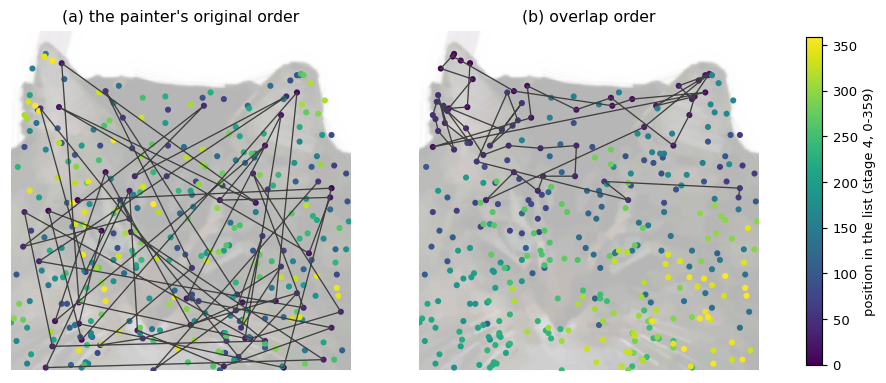

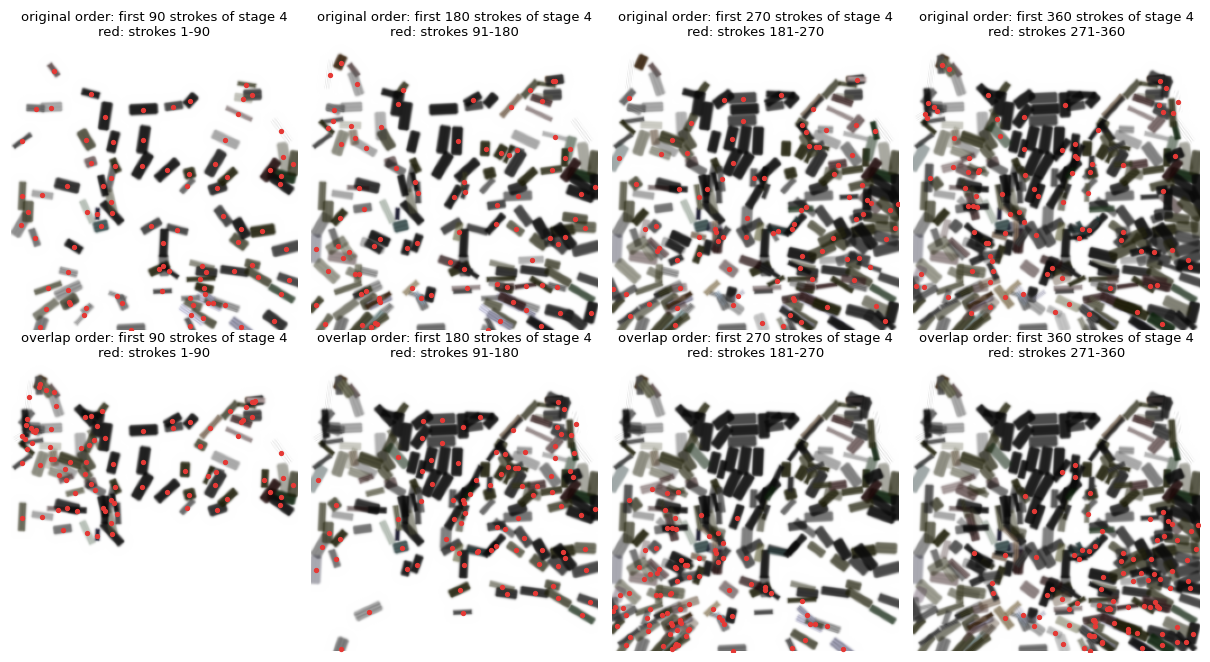

largest pixel difference between the finished paintings of the two orders: 5.96e-08


In [5]:
row_l, row_o = z["tokens"][sel[0]], z["tokens_overlap"][sel[0]]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 5.4))
for a, r_, title in ((ax[0], row_l, "(a) the painter's original order"), (ax[1], row_o, "(b) overlap order")):
    xy = T.decode(r_.tolist())[3]["xy"]                       # centres of the 360 strokes of stage 4
    a.imshow(G.render(r_), alpha=0.3)
    a.plot(xy[:60, 0], xy[:60, 1], "-", color="0.25", lw=0.9)
    sc = a.scatter(xy[:, 0], xy[:, 1], c=np.arange(len(xy)), cmap="viridis", s=10)
    a.set(xlim=(0, 256), ylim=(256, 0), title=title)
    a.axis("off")
fig.colorbar(sc, ax=ax, shrink=0.75, label="position in the list (stage 4, 0-359)")
plt.show()


def stage4_only(row, k4):
    '''Only the first k4 strokes of stage 4 on white paper (without the first three stages), to show where they land;
    painted as in brushtokens.render.'''
    import torch
    part = {key: v[:k4] for key, v in T.decode(row.tolist())[3].items()}
    ys_, xs_ = torch.meshgrid(torch.arange(B.SIDE) + 0.5, torch.arange(B.SIDE) + 0.5, indexing="ij")
    with torch.no_grad():
        canvas = B.composite(torch.ones(B.SIDE, B.SIDE, 3), B.Strokes.from_stage(part, B.STAGES[3][:2]), torch.stack([xs_, ys_], -1))
    return canvas.numpy().clip(0, 1)


steps4 = [90, 180, 270, 360]
fig, ax = plt.subplots(2, len(steps4), figsize=(2.9 * len(steps4), 6.4))
for r, (r_, name) in enumerate(((row_l, "original order"), (row_o, "overlap order"))):
    xy = T.decode(r_.tolist())[3]["xy"]
    for c, k4 in enumerate(steps4):
        ax[r, c].imshow(stage4_only(r_, k4))
        new = xy[k4 - 90:k4]
        ax[r, c].scatter(new[:, 0], new[:, 1], s=7, c="#e53935")
        ax[r, c].set(xlim=(0, 256), ylim=(256, 0))
        ax[r, c].set_title(f"{name}: first {k4} strokes of stage 4\nred: strokes {k4 - 89}-{k4}", fontsize=9)
        ax[r, c].axis("off")
plt.tight_layout()
plt.show()
same = float(np.abs(G.render(row_l) - G.render(row_o)).max())
print(f"largest pixel difference between the finished paintings of the two orders: {same:.2e}")

**Figure 8b.** The 360 strokes of stage 4 of one training cat; the colour of each dot is its position in the list, and
the grey line joins the first 60 strokes. (a) The painter's original order: consecutive strokes are scattered over the
whole canvas. (b) The overlap order: it proceeds from top to bottom, and from left to right within a band. The two
paintings are identical.
**Figure 8c.** Only the first 90, 180, 270 and 360 strokes of stage 4 painted on white paper (without the first three
stages); the red dots are the 90 most recent strokes. Top row, the painter's original order: each block of 90 strokes is
spread over the whole face. Bottom row, the overlap order: strokes 1–90 gather on the ears and forehead, strokes 91–180
move down to the eyes, followed by the cheeks, muzzle and chin. The finished paintings are identical; they differ only
in **the order of painting**. To compare the cats that models trained on the two orders actually paint, one has to
compare models trained on each order separately (A and B in Section 4.3.4).

**Table 6.** Mean distance between consecutive strokes (6 training cats). After reordering, the next stroke in the last
stage is on average only about 30 px away (116 px before), and the picture is identical to floating-point precision.
This is a change to the **data**; no rule is applied at sampling time, and every stroke is still decided by the model.

**Reordering after alignment.** When the CAT dataset was added, it turned out to contain upside-down and sideways
cats: "top to bottom" in photograph coordinates can be bottom to top for the upright face. The data of Section 8.6 are
therefore **aligned first (Section 6.2) and then reordered in the aligned coordinates**.

#### 4.3.3 Problem 2: field restriction

**Why the wrong field is chosen.** The layout of a painting is fixed: `BOS`, the stage-1 marker, then for every stroke
the five tokens x, y, angle, size and colour in turn, and `EOS` after the four stages (Section 4.2). The third token of
the sequence is therefore always an x, the fourth always a y, and so on. The trial's model chooses among all 7,499
tokens at every position, but only 256 of them are legal at an x position (3.4%), and only 36 at a size position
(0.5%). As long as the model gives a little probability to each of the thousands of illegal tokens, sampling at
temperature 1 can pick one of them. A painting has 3,046 tokens, and a single token in the wrong field makes the whole
painting impossible to convert back into strokes: if each token goes wrong with probability 1%, the probability that
all 3,046 are correct is already below $10^{-13}$ (Appendix A). In the trial about 15% of tokens fell in the wrong
field, so not one of the 256 samples could be drawn.

**The fix: each field chooses only among its own tokens.** The fix is implemented in three steps (`brushgpt.py`):

1. **List the allowed range of every position** (`layout`): from the fixed layout, record for every position of the
   sequence which field it belongs to and the smallest and largest token index it allows (Table 6b). For example, an x
   position allows only the 256 bins of x, a colour position only the 6,912 paints, and the position of the stage-$k$
   marker only that one marker.
2. **Turn it into a mask** (`allowed`): turn this table into a Boolean "position × token" matrix $A$; $A_{t,v} = 1$
   means that position $t$ allows token $v$.
3. **Remove the disallowed tokens from the softmax** (`field_logits`): after the model computes the score of every
   token, the scores with $A_{t,v} = 0$ are set to $-\infty$; after the softmax these tokens have probability exactly 0
   and can never be chosen.

The mask is used in **training, the validation loss and sampling**, so the model learns under this restriction, and the
distribution at sampling time matches that of training. Formally it is the
$p_\theta(x_t = v \mid x_{<t}) \propto A_{t,v}\exp(\mathbf h_t^\top \mathbf e_v)$ of Section 5.1; it is equivalent to
one output layer per field, with weights shared with the input embedding.

**What it restricts and what it does not.** The mask restricts only "which kind" each position chooses: an x position
can choose only among the 256 values of x. Which x, which colour and which size are still decided entirely by the
model; what is fixed is only the layout of the data, not the content of the picture. This design was adopted on
2026-10-11 with the project owner's agreement: the question "is this a change of architecture or a patch?" was put to
the owner to decide (Appendix A). With the mask, illegal tokens have probability zero, so "all 256 samples can be
decoded" is guaranteed by construction and cannot be taken as evidence of model quality; quality is measured by the
metrics of Sections 7–8.

,allowed token indices,tokens to choose from,share of vocabulary
kind of position,,,
BOS,0,1,0.01%
EOS,1,1,0.01%
stage markers,2-6,5,0.07%
x,7-262,256,3.41%
y,263-518,256,3.41%
angle,519-550,32,0.43%
size,551-586,36,0.48%
colour,"587-7,498",6912,92.17%


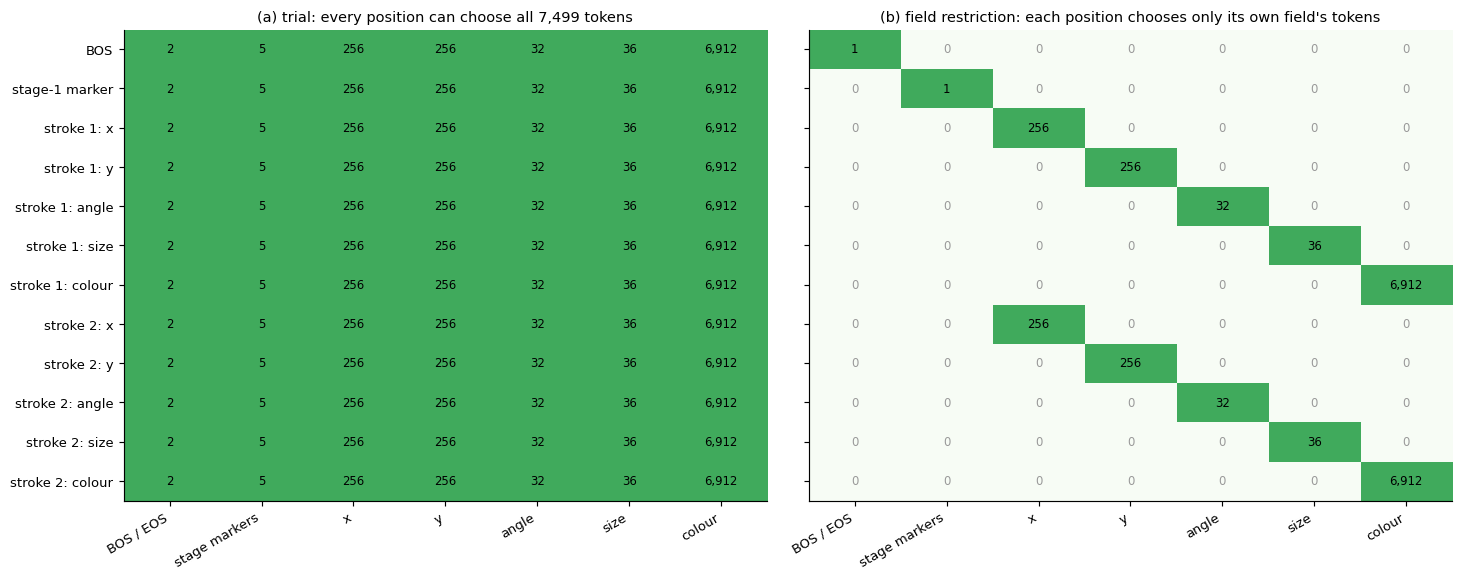

In [6]:
SPANS = [("BOS", T.BOS, T.BOS), ("EOS", T.EOS, T.EOS), ("stage markers", T.STAGE0, T.STAGE0 + len(B.STAGES) - 1),
         ("x", T.OFFSET["x"], T.OFFSET["y"] - 1), ("y", T.OFFSET["y"], T.OFFSET["angle"] - 1),
         ("angle", T.OFFSET["angle"], T.OFFSET["size"] - 1), ("size", T.OFFSET["size"], T.OFFSET["paint"] - 1),
         ("colour", T.OFFSET["paint"], T.VOCAB - 1)]
display(pd.DataFrame([{"kind of position": n, "allowed token indices": f"{lo:,}-{hi:,}" if hi > lo else f"{lo:,}",
                       "tokens to choose from": hi - lo + 1, "share of vocabulary": f"{(hi - lo + 1) / T.VOCAB:.2%}"}
                      for n, lo, hi in SPANS]).set_index("kind of position"))
GROUPS = [("BOS / EOS", T.BOS, T.EOS), ("stage markers", T.STAGE0, T.STAGE0 + len(B.STAGES) - 1)] + [s_ for s_ in SPANS[3:]]
POS = list(range(12))
pos_names = ["BOS", "stage-1 marker"] + [f"stroke {i + 1}: {f}" for i in range(2) for f in ("x", "y", "angle", "size", "colour")]
with_mask = np.array([[max(0, min(int(G.HI[p]), hi) - max(int(G.LO[p]), lo) + 1) for _, lo, hi in GROUPS] for p in POS])
no_mask = np.array([[hi - lo + 1 for _, lo, hi in GROUPS] for _ in POS])
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), sharey=True)
for a, M_, title in ((ax[0], no_mask, "(a) trial: every position can choose all 7,499 tokens"),
                     (ax[1], with_mask, "(b) field restriction: each position chooses only its own field's tokens")):
    a.imshow(M_ > 0, cmap="Greens", vmin=0, vmax=1.6, aspect="auto")
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            a.text(j, i, f"{M_[i, j]:,}" if M_[i, j] else "0", ha="center", va="center", fontsize=8, color="k" if M_[i, j] else "0.6")
    a.set_xticks(range(len(GROUPS)))
    a.set_xticklabels([g[0] for g in GROUPS], rotation=30, ha="right")
    a.set_yticks(range(len(POS)))
    a.set_yticklabels(pos_names)
    a.set_title(title, fontsize=10)
    a.grid(False)
plt.tight_layout()
plt.show()

**Table 6b** (top). The range of tokens each kind of position allows; which kind each position of the sequence is
follows from the fixed layout of Section 4.2.
**Figure 8d** (bottom). The number of tokens each of the first 12 positions of the sequence (`BOS`, the stage-1 marker
and the five fields of the first two strokes) can choose, split by the field the tokens belong to. (a) The trial: every
position can choose tokens of any field; for example, a position meant for x can also pick one of the 6,912 colours.
(b) With the field restriction, each position keeps only its own field's cell (green), and all others are 0.

#### 4.3.4 After the fixes: the first version that paints

Small data (C) adds both the overlap order and the field restriction, and increases the training cats to 1,639, with
all other settings as in the trial. It changes three things at once; to separate them, `tools/modal_brushgpt.py`
defines two control runs that use the same data as C (1,639 training cats, 153 validation cats) and the same training
settings: **A** is the trial's setting (the original stroke order, no field restriction), and **B** is A plus the
overlap order; C is then B plus the field restriction. A and B left no results at the time, so I retrained them with
the same settings on a Colab T4 (Table 6c).

**Table 6c.** The trial, A, B and Small data (C) at their best steps. The trial is quoted from the development log of
2026-10-11, §2; A, B and C come from their saved training logs and evaluations. The trial's validation set is
different (82 cats), so its loss can be compared only roughly.

| | Trial | A | B | Small data (C) |
|---|---|---|---|---|
| Stroke order | The painter's original order | The painter's original order | Overlap order | Overlap order |
| Field restriction | None | None | None | Yes |
| Training cats | 809 | 1,639 | 1,639 | 1,639 |
| Best validation loss | 4.296 | 4.230 | 4.054 | 4.042 |
| Loss of the next stroke's `x` position | 5.53 | 5.50 | 4.65 | 4.66 |
| Share of tokens in the correct field | 84.5% | 82.9% | 46.6% | 100% (guaranteed by the restriction) |
| Decodable samples out of 256 | 0 | 0 | 0 | 256 |

Comparing adjacent columns in turn, each step changes only one condition:

* **Trial → A (twice as many training cats)**: the loss of `x` is still 5.50, almost equal to the 5.55 (ln 256) of
  guessing, and nothing can be drawn. The problem is not too little data.
* **A → B (only the stroke order changes)**: the loss of `x` falls from 5.50 to 4.65. The fall in the loss of `x` comes
  from the overlap order (Section 4.3.2).
* **B → C (only the field restriction is added)**: the validation loss hardly changes (4.054 → 4.042; `x` 4.65 →
  4.66), yet the number of decodable samples goes from 0 to 256. The loss is measured under teacher forcing, where every
  position follows the real preceding tokens; that the two losses are almost the same shows that, in this setting, B
  already puts almost all of its probability on the correct field. Sampling, however, follows the model's own preceding
  tokens, and once B picks one token in a wrong field it cannot recover: after the first error, an average of 61% of
  tokens fall in a wrong field. The field restriction makes tokens of a wrong field impossible to pick (Section 4.3.3),
  and only then does the problem disappear.

B's share of tokens in the wrong field (53.4%) is higher than A's (17.1%); I did not run a separate experiment to find
out why. C is the first version that paints (the Small data row of Figure 1).

## References

1. Z. Huang, W. Heng, S. Zhou. Learning to Paint with Model-based Deep Reinforcement Learning. *ICCV*, 2019.
2. Z. Zou, T. Shi, S. Qiu, Y. Yuan, Z. Shi. Stylized Neural Painting. *CVPR*, 2021.
3. S. Liu et al. Paint Transformer: Feed Forward Neural Painting with Stroke Prediction. *ICCV*, 2021.
4. J. Singh, C. Smith, J. Echevarria, L. Zheng. Intelli-Paint: Towards Developing More Human-Intelligible Painting Agents. *ECCV*, 2022.
5. Y. Tang et al. AttentionPainter: An Efficient and Adaptive Stroke Predictor for Scene Painting. arXiv:2410.16418, 2024.
6. Y. Jiang et al. Birth of a Painting: Differentiable Brushstroke Reconstruction. arXiv:2511.13191, 2025.
7. Y. Qin et al. Data-Efficient Brushstroke Generation with Diffusion Models for Oil Painting. arXiv:2603.01103, 2026.
8. D. Ha, D. Eck. A Neural Representation of Sketch Drawings. *ICLR*, 2018.
9. L. S. F. Ribeiro, T. Bui, J. Collomosse, M. Ponti. Sketchformer: Transformer-based Representation for Sketched Structure. *CVPR*, 2020.
10. E. Peruzzo et al. Interactive Neural Painting. *Computer Vision and Image Understanding*, 2023. arXiv:2307.16441.
11. Wen et al. PaintCopilot: Modeling Painting as Autonomous Artistic Continuation. arXiv:2605.20941, 2026.
12. R. Wu, W. Su, K. Ma, J. Liao. IconShop: Text-Guided Vector Icon Synthesis with Autoregressive Transformers. *ACM TOG (SIGGRAPH Asia)*, 2023.
13. Z. Tang et al. StrokeNUWA: Tokenizing Strokes for Vector Graphic Synthesis. *ICML*, 2024.
14. Y. Song et al. ProcessPainter: Learn Painting Process from Sequence Data. arXiv:2406.06062, 2024.
15. L. Zhang, C. Yan, Y. Guo, J. Xing, M. Agrawala. Generating Past and Future in Digital Painting Processes. *ACM TOG* 44(4), 2025.
16. B. Chen et al. Inverse Painting: Reconstructing the Painting Process. *SIGGRAPH Asia*, 2024.
17. M. Pobitzer et al. Loomis Painter: Reconstructing the Painting Process. arXiv:2511.17344, 2025.
18. Y. Choi, Y. Uh, J. Yoo, J.-W. Ha. StarGAN v2: Diverse Image Synthesis for Multiple Domains. *CVPR*, 2020. (AFHQ dataset)
19. W. Zhang, J. Sun, X. Tang. Cat Head Detection – How to Effectively Exploit Shape and Texture Features. *ECCV*, 2008. (CAT dataset)
20. K. He, X. Chen, S. Xie, Y. Li, P. Dollár, R. Girshick. Masked Autoencoders Are Scalable Vision Learners. *CVPR*, 2022.
21. Y. Xu, J. Zhang, Q. Zhang, D. Tao. ViTPose: Simple Vision Transformer Baselines for Human Pose Estimation. *NeurIPS*, 2022.
22. A. Radford, J. Wu, R. Child, D. Luan, D. Amodei, I. Sutskever. Language Models are Unsupervised Multitask Learners. OpenAI, 2019.
23. H. Touvron et al. LLaMA: Open and Efficient Foundation Language Models. arXiv:2302.13971, 2023.
24. J. Su, Y. Lu, S. Pan, A. Murtadha, B. Wen, Y. Liu. RoFormer: Enhanced Transformer with Rotary Position Embedding. arXiv:2104.09864, 2021.
25. N. Shazeer. GLU Variants Improve Transformer. arXiv:2002.05202, 2020.
26. B. Zhang, R. Sennrich. Root Mean Square Layer Normalization. *NeurIPS*, 2019.
27. I. Loshchilov, F. Hutter. Decoupled Weight Decay Regularization. *ICLR*, 2019.
28. M. Heusel, H. Ramsauer, T. Unterthiner, B. Nessler, S. Hochreiter. GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium. *NeurIPS*, 2017.
29. M. Bińkowski, D. J. Sutherland, M. Arbel, A. Gretton. Demystifying MMD GANs. *ICLR*, 2018.
30. A. Radford et al. Learning Transferable Visual Models From Natural Language Supervision. *ICML*, 2021.
31. X. Xu, K. D. D. Willis, J. G. Lambourne, C.-Y. Cheng, P. K. Jayaraman, Y. Furukawa. SkexGen: Autoregressive Generation of CAD Construction Sequences with Disentangled Codebooks. *ICML*, 2022.
32. P. Litwinowicz. Processing Images and Video for an Impressionist Effect. *SIGGRAPH*, 1997.
33. A. Hertzmann. Painterly Rendering with Curved Brush Strokes of Multiple Sizes. *SIGGRAPH*, 1998.
34. J. Hays, I. Essa. Image and Video Based Painterly Animation. *NPAR*, 2004.
35. M. A. Kowalski, L. Markosian, J. D. Northrup, L. Bourdev, R. Barzel, L. S. Holden, J. F. Hughes. Art-Based Rendering of Fur, Grass, and Trees. *SIGGRAPH*, 1999.
36. R. Wagner, S. Schulz, M. Reimann, A. Semmo, J. Döllner, M. Trapp. Art-directable Stroke-based Rendering on Mobile Devices. *VMV*, pp. 173–180, 2023.
37. T. Wang, J. Collomosse, A. Hunter, D. Greig. Learnable Stroke Models for Example-based Portrait Painting. *BMVC*, 2013.
38. M. Zhao, S.-C. Zhu. Portrait Painting Using Active Templates. *NPAR*, pp. 117–124, 2011.
39. K. Zeng, M. Zhao, C. Xiong, S.-C. Zhu. From Image Parsing to Painterly Rendering. *ACM TOG* 29(1), 2009.
40. M. Chai, T. Shao, H. Wu, Y. Weng, K. Zhou. AutoHair: Fully Automatic Hair Modeling from a Single Image. *ACM TOG* 35(4), 2016.
41. V. Sklyarova, B. Kabadayi, A. Yiannakidis, G. Becherini, M. J. Black, J. Thies. NeuralFur: Animal Fur Reconstruction From Multi-View Images. arXiv:2601.12481, 2026.
42. M. P. Salisbury, M. T. Wong, J. F. Hughes, D. H. Salesin. Orientable Textures for Image-Based Pen-and-Ink Illustration. *SIGGRAPH*, 1997.
43. Z. Tong, X. Wang, S. Yuan, X. Chen, J. Wang, X. Fang. Im2Oil: Stroke-Based Oil Painting Rendering with Linearly Controllable Fineness via Adaptive Sampling. *ACM MM*, 2022.
44. Y. Tang, Y. Wang, et al. AttentionPainter: An Efficient and Adaptive Stroke Predictor for Scene Painting. *IEEE TVCG*, 2025（arXiv:2410.16418）.
45. J. Singh, L. Zheng. Combining Semantic Guidance and Deep Reinforcement Learning for Generating Human Level Paintings. *CVPR*, 2021.
46. J. P. Collomosse, P. M. Hall. Painterly Rendering using Image Salience. *Eurographics UK*, pp. 122–128, 2002.
47. D. Neulander. Painterly Picture Generation. US Patent 9,767,582 B2, 2017.
48. R. Yi, Y.-J. Liu, Y.-K. Lai, P. L. Rosin. APDrawingGAN: Generating Artistic Portrait Drawings from Face Photos with Hierarchical GANs. *CVPR*, 2019.
49. A. Santella, D. DeCarlo. Abstracted Painterly Renderings Using Eye-Tracking Data. *NPAR*, 2002.
50. T. Lindemeier, M. Spicker, O. Deussen. Artistic Composition for Painterly Rendering. *VMV*, 2016.
51. Z. Hu, Y. Chen, J. Yao, B. Ni. PaintFlow: A Unified Framework for Interactive Oil Paintings Editing and Generation. arXiv:2512.08534, 2025.
52. J. E. Kyprianidis, J. Döllner. Image Abstraction by Structure Adaptive Filtering. *EG UK Theory and Practice of Computer Graphics*, pp. 51–58, 2008.
53. H. Kang, S. Lee, C. K. Chui. Coherent Line Drawing. *NPAR*, pp. 43–50, 2007.
54. D. Kotovenko, M. Wright, A. Heimbrecht, B. Ommer. Rethinking Style Transfer: From Pixels to Parameterized Brushstrokes. *CVPR*, 2021.
55. D. DeCarlo, A. Santella. Stylization and Abstraction of Photographs. *ACM TOG* 21(3)（SIGGRAPH）, pp. 769–776, 2002.
56. T. Hu, R. Yi, H. Zhu, L. Liu, J. Peng, Y. Wang, C. Wang, L. Ma. Stroke-based Neural Painting and Stylization with Dynamically Predicted Painting Region（Compositional Neural Painter）. *ACM MM*, 2023.
57. R. Nakano. Neural Painters: A Learned Differentiable Constraint for Generating Brushstroke Paintings. arXiv:1904.08410, 2019（NeurIPS Workshop on Machine Learning for Creativity and Design）.
58. L. Liu, Y. Wang, L. Zhu, L. Liao, Z. Zheng. Look, Compare and Draw: Differential Query Transformer for Automatic Oil Painting. arXiv:2603.27720, 2026.
59. J. Ho, T. Salimans. Classifier-Free Diffusion Guidance. arXiv:2207.12598, 2022.